# Notebook 02 — Complete Retrieval Pipeline
## University RAG

This notebook builds a **complete, reproducible, and research-oriented retrieval pipeline** for Persian university documents.

## Goal

Convert a user query into a ranked list of relevant evidence chunks.

The notebook includes:

- input validation for Notebook 01 outputs
- Persian query normalization
- a reproducible retrieval evaluation dataset
- BM25 sparse retrieval
- dense retrieval with multilingual embedding models
- FAISS indexing
- optional ChromaDB persistence
- hybrid retrieval with Reciprocal Rank Fusion
- metadata-aware filtering
- duplicate removal and MMR diversification
- neighboring-chunk expansion
- cross-encoder reranking
- robustness tests
- ablation studies
- retrieval metrics and error analysis
- a reusable `UniversityRetriever` class

## Input

```text
data/processed/
├── chunks.parquet
├── documents.parquet
├── metadata.json
├── quality_report.json
└── summary.json
```

## Main Outputs

```text
data/retrieval/
├── evaluation/
├── embeddings/
├── indexes/
├── chroma/
├── results/
├── reports/
└── logs/
```

## Position in the RAG Pipeline

```text
Prepared Chunks
      ↓
Query Normalization
      ↓
BM25 + Dense Retrieval
      ↓
Hybrid Fusion
      ↓
Metadata Filtering
      ↓
Deduplication / MMR
      ↓
Cross-Encoder Reranking
      ↓
Top-k Evidence Chunks
      ↓
Notebook 03: Answer Generation
```

## Out of Scope

This notebook does **not** generate the final answer with an LLM. It also does not implement the final prompt, answer citations, faithfulness evaluation, FastAPI, or React.

> **Corrected evaluation version 2.1**
>
> This version fixes document-level metric inflation by collapsing repeated
> chunks from the same document before calculating Recall, nDCG, and MAP.
> It also adds bounded-metric integrity checks, whole-word query expansion,
> metadata-aware article-number prioritization, and provisional labeling for
> results selected from the automatically generated Silver Benchmark.

# 1. Design Decisions

1. **Evaluate before selecting a retriever.**  
   The notebook compares retrieval methods instead of selecting a model only from a public leaderboard.

2. **Keep sparse and dense retrieval.**  
   BM25 is useful for exact terms, article numbers, years, and regulation names. Dense retrieval is useful for natural and paraphrased questions.

3. **Use exact FAISS search for this dataset.**  
   The dataset is small, so `IndexFlatIP` provides exact search without approximation error.

4. **Use normalized embeddings.**  
   L2-normalized vectors with inner-product search are used as cosine similarity.

5. **Separate a silver benchmark from a gold benchmark.**  
   The notebook can automatically create a reproducible silver benchmark. A manually reviewed gold file is preferred for the final report.

6. **Cache all expensive outputs.**  
   Document embeddings, indexes, benchmark results, and reranker outputs are saved and reused.

7. **Continue when an optional component fails.**  
   ChromaDB, a large embedding model, or a reranker may be skipped without stopping the complete baseline pipeline.

8. **Evaluate retrieval separately from answer generation.**  
   Metrics in this notebook measure whether the correct evidence is retrieved, not whether an LLM writes a good answer.

9. **Preserve source metadata.**  
   Every result keeps the document, page, article, note, category, and chunk identifiers required for later citations.

10. **Keep the final retriever reusable.**  
    The final `UniversityRetriever` class can later be imported by the backend.

# 2. Environment and Configuration

The notebook reads its settings from `retrieval_config.yaml`.

The default setup runs:

- BM25
- multilingual MiniLM
- multilingual E5
- FAISS
- hybrid RRF
- multilingual cross-encoder reranking

Larger models such as BGE-M3 are included as optional experiments. They can be enabled in the configuration file.

In [1]:
from __future__ import annotations

import ast
import contextlib
import hashlib
import importlib.metadata as importlib_metadata
import json
import logging
import math
import os
import pickle
import platform
import random
import re
import shutil
import sys
import time
import unicodedata
from collections import Counter, defaultdict
from dataclasses import dataclass, asdict
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable, Optional, Sequence

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import torch
import yaml
from hazm import Normalizer, word_tokenize
from IPython.display import display, Markdown
from rank_bm25 import BM25Okapi
from sentence_transformers import CrossEncoder, SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from tqdm.auto import tqdm

PIPELINE_STARTED_AT = time.perf_counter()
RUN_STARTED_UTC = datetime.now(timezone.utc).isoformat()

In [2]:
def discover_project_root(start: Optional[Path] = None) -> Path:
    # Find the University_RAG project root from the current directory.
    start = (start or Path.cwd()).resolve()

    for candidate in [start, *start.parents]:
        if (
            (candidate / "data").exists()
            and (
                (candidate / "notebooks").exists()
                or (candidate / "requirements.txt").exists()
            )
        ):
            return candidate

    if start.name.lower() == "notebooks":
        return start.parent

    raise FileNotFoundError(
        "Project root was not found. Place this notebook inside "
        "University_RAG/notebooks and start Jupyter from the project root."
    )


PROJECT_ROOT = discover_project_root()
CONFIG_PATH = PROJECT_ROOT / "retrieval_config.yaml"

DEFAULT_CONFIG = {
    "project": {
        "name": "University_RAG",
        "seed": 42,
        "language": "fa",
    },
    "paths": {
        "chunks": "data/processed/chunks.parquet",
        "documents": "data/processed/documents.parquet",
        "metadata": "data/processed/metadata.json",
        "quality_report": "data/processed/quality_report.json",
        "summary": "data/processed/summary.json",
        "retrieval_root": "data/retrieval",
        "evaluation": "data/retrieval/evaluation",
        "embeddings": "data/retrieval/embeddings",
        "indexes": "data/retrieval/indexes",
        "chroma": "data/retrieval/chroma",
        "results": "data/retrieval/results",
        "reports": "data/retrieval/reports",
        "figures": "data/retrieval/reports/figures",
        "logs": "data/retrieval/logs",
    },
    "input": {
        "include_needs_review": True,
        "drop_invalid_documents": True,
        "minimum_chunk_tokens": 1,
    },
    "query": {
        "normalize_persian": True,
        "normalize_digits": True,
        "remove_diacritics": True,
        "remove_extra_spaces": True,
        "use_stopwords_for_bm25": True,
    },
    "bm25": {
        "enabled": True,
        "k1": 1.5,
        "b": 0.75,
    },
    "embedding_models": [
        {
            "name": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
            "alias": "multilingual_minilm",
            "enabled": True,
            "query_prefix": "",
            "passage_prefix": "",
            "trust_remote_code": False,
            "batch_size": 32,
            "max_seq_length": 512,
        },
        {
            "name": "intfloat/multilingual-e5-base",
            "alias": "multilingual_e5_base",
            "enabled": True,
            "query_prefix": "query: ",
            "passage_prefix": "passage: ",
            "trust_remote_code": False,
            "batch_size": 16,
            "max_seq_length": 512,
        },
        {
            "name": "BAAI/bge-m3",
            "alias": "bge_m3",
            "enabled": False,
            "query_prefix": "",
            "passage_prefix": "",
            "trust_remote_code": True,
            "batch_size": 8,
            "max_seq_length": 1024,
        },
        {
            "name": "jinaai/jina-embeddings-v3",
            "alias": "jina_v3",
            "enabled": False,
            "query_prefix": "",
            "passage_prefix": "",
            "trust_remote_code": True,
            "batch_size": 8,
            "max_seq_length": 1024,
        },
    ],
    "dense": {
        "default_model_alias": "multilingual_e5_base",
        "normalize_embeddings": True,
        "faiss_index_type": "flat_ip",
        "rebuild_embeddings": False,
        "rebuild_indexes": False,
    },
    "chroma": {
        "enabled": True,
        "rebuild_collection": False,
        "collection_prefix": "university_rag",
        "batch_size": 128,
    },
    "retrieval": {
        "candidate_k": 30,
        "final_k": 5,
        "evaluation_k_values": [1, 3, 5, 10, 20],
        "rrf_k": 60,
        "bm25_weight": 1.0,
        "dense_weight": 1.0,
        "maximum_chunks_per_document": 3,
        "deduplicate": True,
        "deduplication_threshold": 0.92,
        "use_mmr": True,
        "mmr_lambda": 0.75,
        "expand_neighbors": False,
        "neighbor_window": 1,
    },
    "reranker": {
        "enabled": True,
        "model_name": "cross-encoder/mmarco-mMiniLMv2-L12-H384-v1",
        "candidate_k": 20,
        "final_k": 5,
        "batch_size": 16,
        "max_length": 512,
    },
    "evaluation": {
        "prefer_gold_file": True,
        "gold_filename": "retrieval_questions_gold.csv",
        "silver_filename": "retrieval_questions_silver.csv",
        "silver_queries_per_document": 3,
        "silver_max_queries": 60,
        "include_unanswerable_queries": True,
        "unanswerable_query_count": 5,
        "random_seed": 42,
    },
    "robustness": {
        "enabled": True,
        "variants_per_query": 4,
    },
    "advanced": {
        "query_expansion_enabled": True,
        "parent_child_enabled": True,
        "score_threshold_calibration": True,
    },
}


def deep_merge(default: dict, custom: dict) -> dict:
    result = dict(default)
    for key, value in (custom or {}).items():
        if isinstance(value, dict) and isinstance(result.get(key), dict):
            result[key] = deep_merge(result[key], value)
        else:
            result[key] = value
    return result


if not CONFIG_PATH.exists():
    CONFIG_PATH.write_text(
        yaml.safe_dump(DEFAULT_CONFIG, allow_unicode=True, sort_keys=False),
        encoding="utf-8",
    )
    print(f"Created configuration file: {CONFIG_PATH}")

with CONFIG_PATH.open("r", encoding="utf-8") as file:
    CONFIG = deep_merge(DEFAULT_CONFIG, yaml.safe_load(file) or {})

SEED = int(CONFIG["project"]["seed"])
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

PATHS = {
    key: PROJECT_ROOT / value
    for key, value in CONFIG["paths"].items()
}

for key in [
    "retrieval_root",
    "evaluation",
    "embeddings",
    "indexes",
    "chroma",
    "results",
    "reports",
    "figures",
    "logs",
]:
    PATHS[key].mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("CONFIG_PATH:", CONFIG_PATH)
print(yaml.safe_dump(CONFIG, allow_unicode=True, sort_keys=False))

PROJECT_ROOT: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG
CONFIG_PATH: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\retrieval_config.yaml
project:
  name: University_RAG
  seed: 42
  language: fa
paths:
  chunks: data/processed/chunks.parquet
  documents: data/processed/documents.parquet
  metadata: data/processed/metadata.json
  quality_report: data/processed/quality_report.json
  summary: data/processed/summary.json
  retrieval_root: data/retrieval
  evaluation: data/retrieval/evaluation
  embeddings: data/retrieval/embeddings
  indexes: data/retrieval/indexes
  chroma: data/retrieval/chroma
  results: data/retrieval/results
  reports: data/retrieval/reports
  figures: data/retrieval/reports/figures
  logs: data/retrieval/logs
input:
  include_needs_review: true
  drop_invalid_documents: true
  minimum_chunk_tokens: 1
query:
  normalize_persian: true
  normalize_digits: true
  remove_diacritics: true
  remove_extra_spaces: true
  use_stopwords_for_bm25: true
bm25:
  enabled: true
  k1

In [3]:
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
LOG_PATH = PATHS["logs"] / f"retrieval_pipeline_{RUN_ID}.log"

logger = logging.getLogger("UniversityRAG.Retrieval")
logger.setLevel(logging.INFO)
logger.handlers.clear()

file_handler = logging.FileHandler(LOG_PATH, encoding="utf-8")
file_handler.setFormatter(
    logging.Formatter("%(asctime)s | %(levelname)s | %(message)s")
)
logger.addHandler(file_handler)

stream_handler = logging.StreamHandler(sys.stdout)
stream_handler.setFormatter(logging.Formatter("%(levelname)s | %(message)s"))
logger.addHandler(stream_handler)

STAGE_TIMINGS: dict[str, float] = {}
PIPELINE_ERRORS: list[dict[str, Any]] = []
PIPELINE_WARNINGS: list[dict[str, Any]] = []


@contextlib.contextmanager
def timed_stage(name: str):
    started = time.perf_counter()
    logger.info("START STAGE: %s", name)
    try:
        yield
    except Exception:
        logger.exception("FAILED STAGE: %s", name)
        raise
    finally:
        elapsed = round(time.perf_counter() - started, 3)
        STAGE_TIMINGS[name] = elapsed
        logger.info("END STAGE: %s | %.3f sec", name, elapsed)


def record_error(stage: str, message: str, **context: Any) -> None:
    item = {
        "stage": stage,
        "message": str(message),
        "context": context,
        "timestamp": datetime.now(timezone.utc).isoformat(),
    }
    PIPELINE_ERRORS.append(item)
    logger.error("%s | %s | %s", stage, message, context)


def record_warning(stage: str, message: str, **context: Any) -> None:
    item = {
        "stage": stage,
        "message": str(message),
        "context": context,
        "timestamp": datetime.now(timezone.utc).isoformat(),
    }
    PIPELINE_WARNINGS.append(item)
    logger.warning("%s | %s | %s", stage, message, context)


logger.info("Retrieval pipeline initialized. Run ID: %s", RUN_ID)

INFO | Retrieval pipeline initialized. Run ID: 20260715_015615


In [4]:
REQUIRED_PACKAGES = [
    "pandas",
    "numpy",
    "pyarrow",
    "PyYAML",
    "hazm",
    "rank-bm25",
    "sentence-transformers",
    "transformers",
    "torch",
    "faiss-cpu",
    "chromadb",
    "scikit-learn",
    "joblib",
    "psutil",
    "matplotlib",
]


def package_version(name: str) -> Optional[str]:
    try:
        return importlib_metadata.version(name)
    except importlib_metadata.PackageNotFoundError:
        return None


PACKAGE_VERSIONS = {
    package: package_version(package)
    for package in REQUIRED_PACKAGES
}
MISSING_PACKAGES = [
    package
    for package, version in PACKAGE_VERSIONS.items()
    if version is None
]

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU_NAME = (
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else None
)

try:
    import faiss
    FAISS_AVAILABLE = True
except Exception as exc:
    faiss = None
    FAISS_AVAILABLE = False
    record_warning("preflight", "FAISS is not available.", error=str(exc))

try:
    import chromadb
    CHROMA_AVAILABLE = True
except Exception as exc:
    chromadb = None
    CHROMA_AVAILABLE = False
    record_warning("preflight", "ChromaDB is not available.", error=str(exc))

if MISSING_PACKAGES:
    print("Missing packages:", MISSING_PACKAGES)
else:
    print("All required packages are installed.")

print("Device:", DEVICE)
print("GPU:", GPU_NAME)
print("FAISS available:", FAISS_AVAILABLE)
print("ChromaDB available:", CHROMA_AVAILABLE)

ENVIRONMENT_INFO = {
    "run_id": RUN_ID,
    "run_started_utc": RUN_STARTED_UTC,
    "python_version": sys.version,
    "python_executable": sys.executable,
    "platform": platform.platform(),
    "machine": platform.machine(),
    "processor": platform.processor(),
    "device": DEVICE,
    "gpu_name": GPU_NAME,
    "physical_memory_gb": round(
        psutil.virtual_memory().total / (1024 ** 3), 2
    ),
    "package_versions": PACKAGE_VERSIONS,
    "faiss_available": FAISS_AVAILABLE,
    "chroma_available": CHROMA_AVAILABLE,
}

display(pd.DataFrame([ENVIRONMENT_INFO]).T.rename(columns={0: "value"}))

All required packages are installed.
Device: cpu
GPU: None
FAISS available: True
ChromaDB available: True


,value
run_id,20260715_015615
run_started_utc,2026-07-14T22:26:15.363820+00:00
python_version,"3.11.3 (tags/v3.11.3:f3909b8, Apr 4 2023, 23:..."
python_executable,D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\.v...
platform,Windows-10-10.0.26200-SP0
machine,AMD64
processor,"Intel64 Family 6 Model 140 Stepping 1, Genuine..."
device,cpu
gpu_name,None
physical_memory_gb,15.7


# 3. Load and Validate Notebook 01 Outputs

This stage checks:

- all required files exist
- chunk IDs are unique
- chunk text is not empty
- required metadata columns exist
- chunk counts match `summary.json`
- invalid documents are excluded
- `needs_review` documents are included or excluded based on configuration

In [5]:
REQUIRED_INPUT_FILES = {
    "chunks": PATHS["chunks"],
    "documents": PATHS["documents"],
    "metadata": PATHS["metadata"],
    "quality_report": PATHS["quality_report"],
    "summary": PATHS["summary"],
}

missing_input_files = [
    name
    for name, path in REQUIRED_INPUT_FILES.items()
    if not path.exists()
]

if missing_input_files:
    raise FileNotFoundError(
        "Required Notebook 01 outputs are missing: "
        f"{missing_input_files}"
    )

with timed_stage("load_notebook01_outputs"):
    chunks_raw_df = pd.read_parquet(PATHS["chunks"], engine="pyarrow")
    documents_df = pd.read_parquet(PATHS["documents"], engine="pyarrow")
    metadata_json = json.loads(PATHS["metadata"].read_text(encoding="utf-8"))
    quality_report = json.loads(
        PATHS["quality_report"].read_text(encoding="utf-8")
    )
    notebook01_summary = json.loads(
        PATHS["summary"].read_text(encoding="utf-8")
    )

print("Raw chunks:", len(chunks_raw_df))
print("Documents:", len(documents_df))
print("Notebook 01 summary:", notebook01_summary)

INFO | START STAGE: load_notebook01_outputs
INFO | END STAGE: load_notebook01_outputs | 0.084 sec
Raw chunks: 316
Documents: 15
Notebook 01 summary: {'run_id': '20260714_232636', 'status': 'completed', 'documents': 15, 'pages': 277, 'chunks': 316, 'documents_ready_for_retrieval': 14, 'documents_needing_review': 1, 'invalid_documents': 0, 'ocr_used_pages': 146, 'errors_count': 0, 'warnings_count': 0, 'total_runtime_seconds': 1816.327, 'next_notebook_input': 'D:\\UNI\\TERM10\\1. NLP\\PROJECT\\University_RAG\\data\\processed\\chunks.parquet'}


In [6]:
REQUIRED_CHUNK_COLUMNS = [
    "chunk_id",
    "document_id",
    "chunk_order",
    "text",
    "token_count",
    "page_start",
    "page_end",
    "title",
    "category",
    "filename",
    "relative_path",
    "validation_status",
]

missing_columns = [
    column
    for column in REQUIRED_CHUNK_COLUMNS
    if column not in chunks_raw_df.columns
]
if missing_columns:
    raise ValueError(
        f"chunks.parquet is missing required columns: {missing_columns}"
    )

input_issues: list[str] = []

duplicate_chunk_ids = int(chunks_raw_df["chunk_id"].duplicated().sum())
empty_chunks = int(
    (chunks_raw_df["text"].fillna("").astype(str).str.strip() == "").sum()
)
missing_document_ids = int(chunks_raw_df["document_id"].isna().sum())
summary_chunk_count = int(notebook01_summary.get("chunks", -1))
summary_mismatch = (
    summary_chunk_count >= 0
    and summary_chunk_count != len(chunks_raw_df)
)

if duplicate_chunk_ids:
    input_issues.append(f"duplicate_chunk_ids:{duplicate_chunk_ids}")
if empty_chunks:
    input_issues.append(f"empty_chunks:{empty_chunks}")
if missing_document_ids:
    input_issues.append(f"missing_document_ids:{missing_document_ids}")
if summary_mismatch:
    input_issues.append(
        f"summary_chunk_count_mismatch:"
        f"{summary_chunk_count}!={len(chunks_raw_df)}"
    )

if input_issues:
    raise ValueError(f"Input validation failed: {input_issues}")

chunks_df = chunks_raw_df.copy()

if bool(CONFIG["input"]["drop_invalid_documents"]):
    chunks_df = chunks_df[
        chunks_df["validation_status"].fillna("invalid") != "invalid"
    ].copy()

if not bool(CONFIG["input"]["include_needs_review"]):
    chunks_df = chunks_df[
        chunks_df["validation_status"].fillna("") == "ready"
    ].copy()

minimum_chunk_tokens = int(CONFIG["input"]["minimum_chunk_tokens"])
chunks_df = chunks_df[
    chunks_df["token_count"].fillna(0) >= minimum_chunk_tokens
].copy()

chunks_df = chunks_df.sort_values(
    ["document_id", "chunk_order"],
    kind="stable",
).reset_index(drop=True)

chunks_df["row_id"] = np.arange(len(chunks_df), dtype=np.int64)

INPUT_VALIDATION = {
    "valid": True,
    "raw_chunk_count": int(len(chunks_raw_df)),
    "retrieval_chunk_count": int(len(chunks_df)),
    "document_count": int(chunks_df["document_id"].nunique()),
    "duplicate_chunk_ids": duplicate_chunk_ids,
    "empty_chunks": empty_chunks,
    "summary_chunk_count": summary_chunk_count,
    "include_needs_review": bool(
        CONFIG["input"]["include_needs_review"]
    ),
    "drop_invalid_documents": bool(
        CONFIG["input"]["drop_invalid_documents"]
    ),
}

display(pd.DataFrame([INPUT_VALIDATION]).T.rename(columns={0: "value"}))

,value
valid,True
raw_chunk_count,316
retrieval_chunk_count,316
document_count,15
duplicate_chunk_ids,0
empty_chunks,0
summary_chunk_count,316
include_needs_review,True
drop_invalid_documents,True


In [7]:
# Show representative input chunks.
sample_columns = [
    "chunk_id",
    "document_id",
    "chunk_order",
    "title",
    "category",
    "page_start",
    "page_end",
    "article",
    "note",
    "token_count",
    "validation_status",
    "text",
]

available_sample_columns = [
    column
    for column in sample_columns
    if column in chunks_df.columns
]

random_sample = chunks_df.sample(
    min(5, len(chunks_df)),
    random_state=SEED,
)[available_sample_columns]

structured_sample = chunks_df[
    chunks_df.get("article", pd.Series(index=chunks_df.index)).notna()
    | chunks_df.get("note", pd.Series(index=chunks_df.index)).notna()
].head(5)[available_sample_columns]

display(Markdown("### Random Chunks"))
display(random_sample)

display(Markdown("### Chunks with Article or Note Metadata"))
display(structured_sample)

### Random Chunks

,chunk_id,document_id,chunk_order,title,category,page_start,page_end,article,note,token_count,validation_status,text
173,chk_8c37a123f3cc0b31,doc_cde80d5de36969b4,23,مجموعه مقررات آموزشی 1402,regulations,8,15,NaN,NaN,481,needs_review,، » پیوسته ارشد کارشناسی « ، » تخصصی ی ها دوره...
33,chk_1c83d241a0d9be33,doc_49c5526926da11d9,2,ainname karshenasi phd msc 1397 (2),master_phd,1,11,NaN,NaN,489,ready,مجاز باقیمانده » » . رشته تحصیلی خود را تغییر ...
165,chk_62fd1047aecd9855,doc_cde80d5de36969b4,15,مجموعه مقررات آموزشی 1402,regulations,7,8,NaN,NaN,500,needs_review,۱۰۸.. ... ... ... ... ... ... ... ... ... .......
78,chk_6483613263d82d63,doc_8437d8390ee97a32,3,شیوه نامه ارشد 97,master_phd,5,6,NaN,NaN,486,ready,۳ - ۱ - ۴ - دانشجوی پذیرفته‌شده موظف است در زم...
93,chk_37bdaf88c3bb231f,doc_8e4636a6b09cad76,3,دستورالعمل شهریه,tuition,1,12,NaN,NaN,465,ready,دانشجویان مهمان و انتقالی دریافت شود . از پردا...


### Chunks with Article or Note Metadata

,chunk_id,document_id,chunk_order,title,category,page_start,page_end,article,note,token_count,validation_status,text
10,chk_f706a3bc8ac4637b,doc_3e96016c373b1322,10,مقررات آموزشی ابلاغی 1402,regulations,9,9,NaN,1,481,ready,"تبصره ۱. گروه آموزشی مربوطه, درس و تعداد واحد ..."
11,chk_25e5b24dcac0bf32,doc_3e96016c373b1322,11,مقررات آموزشی ابلاغی 1402,regulations,9,9,NaN,1,174,ready,. آجازه else از پایان‌نامه Ty ندارد و نها یک ن...
12,chk_c94fd6a7a1ec33e5,doc_3e96016c373b1322,12,مقررات آموزشی ابلاغی 1402,regulations,10,11,NaN,5,481,ready,"تبصره ۵. تاریخ دانش‌آموختگی, روز دفاع و کسب در..."
13,chk_254f65bdd4016dcb,doc_3e96016c373b1322,13,مقررات آموزشی ابلاغی 1402,regulations,10,11,NaN,5,460,ready,ندارد و تنها یک تیمبال « با رعایت سقف مجاز سنز...
14,chk_44dc735540fe0970,doc_3e96016c373b1322,14,مقررات آموزشی ابلاغی 1402,regulations,10,11,NaN,5,237,ready,و بالاتر و ثبت یک اختراع : داخلی gel المللی در...


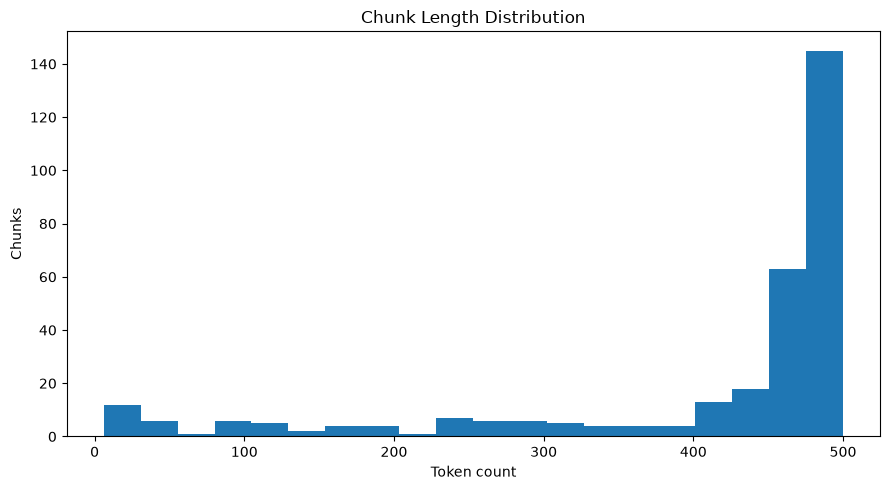

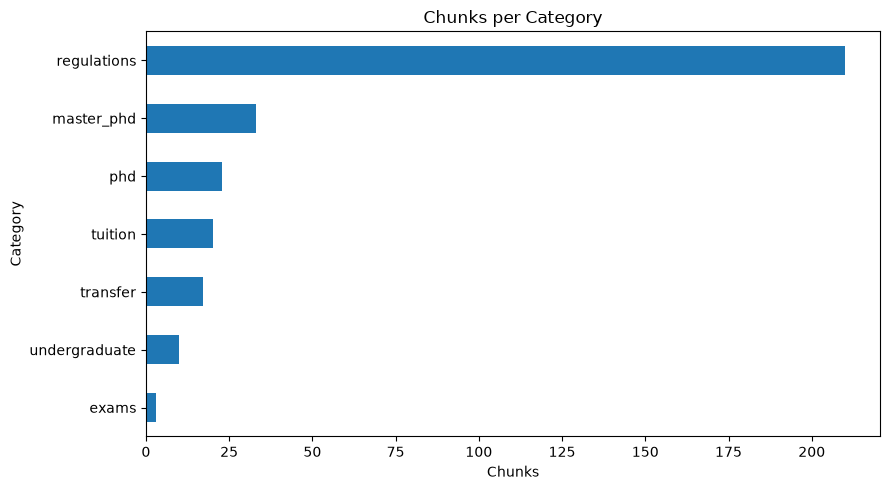

In [8]:
# Input distribution plots.
plt.figure(figsize=(9, 5))
plt.hist(chunks_df["token_count"], bins=20)
plt.title("Chunk Length Distribution")
plt.xlabel("Token count")
plt.ylabel("Chunks")
plt.tight_layout()
plt.savefig(
    PATHS["figures"] / "input_chunk_length_distribution.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

chunks_by_category = (
    chunks_df.groupby("category")
    .size()
    .sort_values()
)

plt.figure(figsize=(9, 5))
chunks_by_category.plot(kind="barh")
plt.title("Chunks per Category")
plt.xlabel("Chunks")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig(
    PATHS["figures"] / "chunks_per_category.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

# 4. Persian Query Normalization

The query normalizer handles:

- Arabic and Persian forms of `ی` and `ک`
- Persian, Arabic, and Latin digits
- diacritics
- half-spaces
- repeated spaces
- punctuation for BM25 tokenization

The original user query is preserved for display and reranking.

In [9]:
PERSIAN_DIGITS = "۰۱۲۳۴۵۶۷۸۹"
ARABIC_DIGITS = "٠١٢٣٤٥٦٧٨٩"
LATIN_DIGITS = "0123456789"

DIGIT_TRANSLATION = str.maketrans(
    PERSIAN_DIGITS + ARABIC_DIGITS,
    LATIN_DIGITS + LATIN_DIGITS,
)

ARABIC_TO_PERSIAN_MAP = str.maketrans(
    {
        "ي": "ی",
        "ى": "ی",
        "ك": "ک",
        "ۀ": "هٔ",
        "ة": "ه",
        "ؤ": "و",
        "إ": "ا",
        "أ": "ا",
    }
)

DIACRITICS_RE = re.compile(
    "["
    "\u0610-\u061A"
    "\u064B-\u065F"
    "\u0670"
    "\u06D6-\u06ED"
    "]"
)

TOKEN_CLEAN_RE = re.compile(
    r"[^\w\u0600-\u06FF\u200c]+",
    flags=re.UNICODE,
)

HAZM_NORMALIZER = Normalizer()

PERSIAN_STOPWORDS = {
    "از", "به", "با", "در", "برای", "که", "این", "آن",
    "را", "و", "یا", "است", "هست", "شود", "شده",
    "چه", "چی", "چگونه", "چطور", "آیا", "یک", "بر",
    "طبق", "مورد", "درباره", "مربوط", "می", "باشد",
}


def normalize_persian_query(text: str) -> str:
    text = str(text or "")
    text = unicodedata.normalize("NFKC", text)

    if bool(CONFIG["query"]["normalize_persian"]):
        text = text.translate(ARABIC_TO_PERSIAN_MAP)
        try:
            text = HAZM_NORMALIZER.normalize(text)
        except Exception:
            pass

    if bool(CONFIG["query"]["normalize_digits"]):
        text = text.translate(DIGIT_TRANSLATION)

    if bool(CONFIG["query"]["remove_diacritics"]):
        text = DIACRITICS_RE.sub("", text)

    text = re.sub(r"\s*\u200c\s*", "\u200c", text)

    if bool(CONFIG["query"]["remove_extra_spaces"]):
        text = re.sub(r"\s+", " ", text)

    return text.strip()


def bm25_tokenize(text: str) -> list[str]:
    normalized = normalize_persian_query(text).lower()
    normalized = TOKEN_CLEAN_RE.sub(" ", normalized)
    tokens = [
        token.strip()
        for token in word_tokenize(normalized)
        if token.strip()
    ]

    if bool(CONFIG["query"]["use_stopwords_for_bm25"]):
        tokens = [
            token
            for token in tokens
            if token not in PERSIAN_STOPWORDS
        ]

    return tokens


normalization_examples = pd.DataFrame(
    {
        "original": [
            "شرایط مهمانی دانشجو چيست؟",
            "ماده ۱۲ آیین‌نامه ۱۴۰۲",
            "نحوه‌ی پرداخت شهريه",
            "آیا دانشجو می تواند انتقالی بگیرد؟",
        ]
    }
)
normalization_examples["normalized"] = normalization_examples[
    "original"
].map(normalize_persian_query)
normalization_examples["bm25_tokens"] = normalization_examples[
    "original"
].map(bm25_tokenize)

display(normalization_examples)

,original,normalized,bm25_tokens
0,شرایط مهمانی دانشجو چيست؟,شرایط مهمانی دانشجو چیست؟,"[شرایط, مهمانی, دانشجو, چیست, ؟]"
1,ماده ۱۲ آیین‌نامه ۱۴۰۲,ماده 12 آیین‌نامه 1402,"[ماده, 12, آیین‌نامه, 1402]"
2,نحوه‌ی پرداخت شهريه,نحوه‌ی پرداخت شهریه,"[نحوه‌ی, پرداخت, شهریه]"
3,آیا دانشجو می تواند انتقالی بگیرد؟,آیا دانشجو می‌تواند انتقالی بگیرد؟,"[دانشجو, می‌تواند, انتقالی, بگیرد, ؟]"


In [10]:
# Prepare retrieval text once.
def build_retrieval_text(row: pd.Series) -> str:
    parts = [
        str(row.get("title", "") or ""),
        str(row.get("category", "") or ""),
        str(row.get("document_type", "") or ""),
        (
            f"ماده {row.get('article')}"
            if pd.notna(row.get("article"))
            else ""
        ),
        (
            f"تبصره {row.get('note')}"
            if pd.notna(row.get("note"))
            else ""
        ),
        str(row.get("text", "") or ""),
    ]
    return normalize_persian_query(
        "\n".join(part for part in parts if part)
    )


chunks_df["retrieval_text"] = chunks_df.apply(
    build_retrieval_text,
    axis=1,
)
chunks_df["bm25_tokens"] = chunks_df["retrieval_text"].map(
    bm25_tokenize
)

assert not (
    chunks_df["retrieval_text"].str.strip() == ""
).any()

display(
    chunks_df[
        [
            "chunk_id",
            "title",
            "article",
            "note",
            "token_count",
            "retrieval_text",
        ]
    ].head(5)
)

,chunk_id,title,article,note,token_count,retrieval_text
0,chk_c28b585674c241ad,مقررات آموزشی ابلاغی 1402,NaN,NaN,493,مقررات آموزشی ابلاغی 1402 regulations regulati...
1,chk_967e963cab8587e8,مقررات آموزشی ابلاغی 1402,NaN,NaN,485,مقررات آموزشی ابلاغی 1402 regulations regulati...
2,chk_47b046d93fd49808,مقررات آموزشی ابلاغی 1402,NaN,NaN,392,مقررات آموزشی ابلاغی 1402 regulations regulati...
3,chk_34fd8834c5a4ddb9,مقررات آموزشی ابلاغی 1402,NaN,NaN,487,مقررات آموزشی ابلاغی 1402 regulations regulati...
4,chk_8b9b51ece231798e,مقررات آموزشی ابلاغی 1402,NaN,NaN,128,مقررات آموزشی ابلاغی 1402 regulations regulati...


# 5. Retrieval Evaluation Dataset

A retrieval system cannot be selected scientifically without relevance labels.

This notebook supports two benchmark levels:

## Gold Benchmark

A manually reviewed file:

```text
data/retrieval/evaluation/retrieval_questions_gold.csv
```

This file is preferred for the final report.

## Silver Benchmark

When the gold file is missing, the notebook creates a deterministic silver benchmark from document titles, article metadata, and representative chunk content.

The silver benchmark is useful for development and regression testing, but it may overestimate performance because some questions are automatically derived from the source text.

## Required Columns

```text
query_id
query
query_type
difficulty
answerable
relevant_chunk_ids
relevant_document_ids
category
notes
```

In [11]:
def json_list(value: Any) -> list[str]:
    if value is None:
        return []

    if isinstance(value, list):
        return [str(item) for item in value]

    if isinstance(value, (tuple, set, np.ndarray)):
        return [str(item) for item in value]

    if isinstance(value, float) and math.isnan(value):
        return []

    text = str(value).strip()
    if not text:
        return []

    try:
        parsed = json.loads(text)
        if isinstance(parsed, list):
            return [str(item) for item in parsed]
    except Exception:
        pass

    try:
        parsed = ast.literal_eval(text)
        if isinstance(parsed, (list, tuple, set)):
            return [str(item) for item in parsed]
    except Exception:
        pass

    return [item.strip() for item in text.split("|") if item.strip()]


def serialize_list(values: Iterable[Any]) -> str:
    return json.dumps(
        [str(value) for value in values],
        ensure_ascii=False,
    )


def clean_title_for_query(title: str) -> str:
    title = normalize_persian_query(title)
    title = re.sub(r"\.pdf$", "", title, flags=re.IGNORECASE)
    title = re.sub(r"[_\-]+", " ", title)
    return re.sub(r"\s+", " ", title).strip()


def content_keywords(text: str, limit: int = 5) -> list[str]:
    tokens = [
        token
        for token in bm25_tokenize(text)
        if len(token) >= 3
        and not token.isdigit()
    ]
    counts = Counter(tokens)
    return [
        token
        for token, _ in counts.most_common(limit)
    ]


def build_silver_benchmark(
    chunks: pd.DataFrame,
    max_queries: int,
    queries_per_document: int,
    seed: int,
) -> pd.DataFrame:
    rng = random.Random(seed)
    rows: list[dict[str, Any]] = []

    for document_id, group in chunks.groupby(
        "document_id",
        sort=False,
    ):
        group = group.sort_values("chunk_order")
        title = clean_title_for_query(group.iloc[0]["title"])
        category = str(group.iloc[0]["category"])
        document_chunk_ids = group["chunk_id"].astype(str).tolist()

        # Query 1: document-title query.
        rows.append(
            {
                "query": f"اطلاعات مربوط به {title} چیست؟",
                "query_type": "title",
                "difficulty": "easy",
                "answerable": True,
                "relevant_chunk_ids": serialize_list([]),
                "relevant_document_ids": serialize_list([document_id]),
                "category": category,
                "notes": "Automatically generated title query.",
            }
        )

        candidates = group.copy()

        # Prefer a chunk with article metadata.
        article_candidates = candidates[
            candidates.get(
                "article",
                pd.Series(index=candidates.index),
            ).notna()
        ]

        if not article_candidates.empty:
            selected = article_candidates.iloc[
                rng.randrange(len(article_candidates))
            ]
            article = str(selected["article"])
            rows.append(
                {
                    "query": (
                        f"ماده {article} در {title} "
                        "درباره چه موضوعی است؟"
                    ),
                    "query_type": "article_lookup",
                    "difficulty": "medium",
                    "answerable": True,
                    "relevant_chunk_ids": serialize_list(
                        [selected["chunk_id"]]
                    ),
                    "relevant_document_ids": serialize_list([document_id]),
                    "category": category,
                    "notes": "Automatically generated article query.",
                }
            )

        # Query from content keywords.
        content_candidates = candidates[
            candidates["token_count"].fillna(0) >= 50
        ]
        if content_candidates.empty:
            content_candidates = candidates

        selected = content_candidates.iloc[
            rng.randrange(len(content_candidates))
        ]
        keywords = content_keywords(
            selected["text"],
            limit=4,
        )

        if keywords:
            keyword_phrase = "، ".join(keywords)
            rows.append(
                {
                    "query": (
                        f"در {title} درباره {keyword_phrase} "
                        "چه توضیحی داده شده است؟"
                    ),
                    "query_type": "content_keywords",
                    "difficulty": "medium",
                    "answerable": True,
                    "relevant_chunk_ids": serialize_list(
                        [selected["chunk_id"]]
                    ),
                    "relevant_document_ids": serialize_list([document_id]),
                    "category": category,
                    "notes": "Automatically generated content query.",
                }
            )

        # Keep the configured number of generated queries per document.
        document_rows = [
            row
            for row in rows
            if json_list(row["relevant_document_ids"]) == [str(document_id)]
        ]
        if len(document_rows) > queries_per_document:
            keep_ids = set(
                id(item)
                for item in document_rows[:queries_per_document]
            )
            rows = [
                row
                for row in rows
                if (
                    json_list(row["relevant_document_ids"]) != [str(document_id)]
                    or id(row) in keep_ids
                )
            ]

    if bool(CONFIG["evaluation"]["include_unanswerable_queries"]):
        unanswerable_queries = [
            "شرایط دریافت وام مسکن کارکنان دانشگاه چیست؟",
            "برنامه حرکت سرویس دانشگاه در روز جمعه چیست؟",
            "شهریه رشته پزشکی دانشگاه تهران چقدر است؟",
            "قیمت غذای سلف در سال آینده چقدر خواهد بود؟",
            "شرایط استخدام هیئت علمی در دانشگاه چیست؟",
            "نتیجه مسابقه فوتبال دانشگاه چه بوده است؟",
            "ساعت کاری کتابخانه در تعطیلات نوروز چیست؟",
        ]
        count = int(
            CONFIG["evaluation"]["unanswerable_query_count"]
        )
        for index, query in enumerate(unanswerable_queries[:count]):
            rows.append(
                {
                    "query": query,
                    "query_type": "unanswerable",
                    "difficulty": "hard",
                    "answerable": False,
                    "relevant_chunk_ids": serialize_list([]),
                    "relevant_document_ids": serialize_list([]),
                    "category": "",
                    "notes": "Out-of-corpus negative query.",
                }
            )

    benchmark = pd.DataFrame(rows)
    benchmark = benchmark.drop_duplicates(
        subset=["query"],
        keep="first",
    ).reset_index(drop=True)

    if len(benchmark) > max_queries:
        positive = benchmark[benchmark["answerable"]].sample(
            min(
                max_queries
                - int((~benchmark["answerable"]).sum()),
                int(benchmark["answerable"].sum()),
            ),
            random_state=seed,
        )
        negative = benchmark[~benchmark["answerable"]]
        benchmark = pd.concat(
            [positive, negative],
            ignore_index=True,
        ).head(max_queries)

    benchmark.insert(
        0,
        "query_id",
        [
            f"silver_q_{index:03d}"
            for index in range(1, len(benchmark) + 1)
        ],
    )
    benchmark["benchmark_type"] = "silver_auto"
    return benchmark

In [12]:
SILVER_PATH = (
    PATHS["evaluation"]
    / CONFIG["evaluation"]["silver_filename"]
)
GOLD_PATH = (
    PATHS["evaluation"]
    / CONFIG["evaluation"]["gold_filename"]
)

with timed_stage("build_or_load_evaluation_benchmark"):
    silver_benchmark_df = build_silver_benchmark(
        chunks=chunks_df,
        max_queries=int(
            CONFIG["evaluation"]["silver_max_queries"]
        ),
        queries_per_document=int(
            CONFIG["evaluation"]["silver_queries_per_document"]
        ),
        seed=int(
            CONFIG["evaluation"]["random_seed"]
        ),
    )
    silver_benchmark_df.to_csv(
        SILVER_PATH,
        index=False,
        encoding="utf-8-sig",
    )

    if (
        bool(CONFIG["evaluation"]["prefer_gold_file"])
        and GOLD_PATH.exists()
    ):
        evaluation_df = pd.read_csv(GOLD_PATH)
        evaluation_df["benchmark_type"] = "gold_manual"
        ACTIVE_BENCHMARK_PATH = GOLD_PATH
    else:
        evaluation_df = silver_benchmark_df.copy()
        ACTIVE_BENCHMARK_PATH = SILVER_PATH

for column in [
    "relevant_chunk_ids",
    "relevant_document_ids",
]:
    evaluation_df[column] = evaluation_df[column].map(json_list)

evaluation_df["answerable"] = evaluation_df["answerable"].map(
    lambda value: (
        value
        if isinstance(value, bool)
        else str(value).strip().lower()
        in {"true", "1", "yes", "y"}
    )
)

print("Active benchmark:", ACTIVE_BENCHMARK_PATH)
print("Benchmark type:", evaluation_df["benchmark_type"].iloc[0])
print("Queries:", len(evaluation_df))
display(evaluation_df.head(15))

INFO | START STAGE: build_or_load_evaluation_benchmark
INFO | END STAGE: build_or_load_evaluation_benchmark | 0.100 sec
Active benchmark: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\retrieval\evaluation\retrieval_questions_silver.csv
Benchmark type: silver_auto
Queries: 37


,query_id,query,query_type,difficulty,answerable,relevant_chunk_ids,relevant_document_ids,category,notes,benchmark_type
0,silver_q_001,اطلاعات مربوط به مقررات آموزشی ابلاغی 1402 چیست؟,title,easy,True,[],[doc_3e96016c373b1322],regulations,Automatically generated title query.,silver_auto
1,silver_q_002,در مقررات آموزشی ابلاغی 1402 درباره دانشگاه، د...,content_keywords,medium,True,[chk_96d047406f8638d9],[doc_3e96016c373b1322],regulations,Automatically generated content query.,silver_auto
2,silver_q_003,اطلاعات مربوط به شیوه‌نامه کارشناسی 97 چیست؟,title,easy,True,[],[doc_481848ae8c106953],undergraduate,Automatically generated title query.,silver_auto
3,silver_q_004,ماده 6 در شیوه‌نامه کارشناسی 97 درباره چه موضو...,article_lookup,medium,True,[chk_d3c0eccb3612acb8],[doc_481848ae8c106953],undergraduate,Automatically generated article query.,silver_auto
4,silver_q_005,در شیوه‌نامه کارشناسی 97 درباره ماده، آموزشی، ...,content_keywords,medium,True,[chk_ba7ba529d2170047],[doc_481848ae8c106953],undergraduate,Automatically generated content query.,silver_auto
5,silver_q_006,اطلاعات مربوط به ainname karshenasi phd msc 13...,title,easy,True,[],[doc_49c5526926da11d9],master_phd,Automatically generated title query.,silver_auto
6,silver_q_007,در ainname karshenasi phd msc 1397 (2) درباره ...,content_keywords,medium,True,[chk_13aee63c9c8213ee],[doc_49c5526926da11d9],master_phd,Automatically generated content query.,silver_auto
7,silver_q_008,اطلاعات مربوط به shivename 1402 چیست؟,title,easy,True,[],[doc_612061131248f51e],regulations,Automatically generated title query.,silver_auto
8,silver_q_009,در shivename 1402 درباره دروس، جبرانی، واحد، آ...,content_keywords,medium,True,[chk_4ace121bcabcefa0],[doc_612061131248f51e],regulations,Automatically generated content query.,silver_auto
9,silver_q_010,اطلاعات مربوط به اطالعیه نیمسال پایان امتحانات...,title,easy,True,[],[doc_6def6b6e442a995c],exams,Automatically generated title query.,silver_auto


In [13]:
# Validate benchmark references.
known_chunk_ids = set(chunks_df["chunk_id"].astype(str))
known_document_ids = set(chunks_df["document_id"].astype(str))

benchmark_reference_issues = []

for row in evaluation_df.itertuples(index=False):
    unknown_chunks = set(row.relevant_chunk_ids) - known_chunk_ids
    unknown_documents = (
        set(row.relevant_document_ids)
        - known_document_ids
    )

    if unknown_chunks:
        benchmark_reference_issues.append(
            {
                "query_id": row.query_id,
                "issue": "unknown_chunk_ids",
                "values": sorted(unknown_chunks),
            }
        )
    if unknown_documents:
        benchmark_reference_issues.append(
            {
                "query_id": row.query_id,
                "issue": "unknown_document_ids",
                "values": sorted(unknown_documents),
            }
        )
    if row.answerable and (
        not row.relevant_chunk_ids
        and not row.relevant_document_ids
    ):
        benchmark_reference_issues.append(
            {
                "query_id": row.query_id,
                "issue": "answerable_query_without_relevance_label",
                "values": [],
            }
        )

if benchmark_reference_issues:
    display(pd.DataFrame(benchmark_reference_issues))
    raise ValueError(
        "The active evaluation benchmark has invalid relevance labels."
    )

benchmark_summary = (
    evaluation_df.groupby(
        ["benchmark_type", "query_type", "difficulty", "answerable"],
        dropna=False,
    )
    .size()
    .rename("count")
    .reset_index()
)

display(benchmark_summary)

,benchmark_type,query_type,difficulty,answerable,count
0,silver_auto,article_lookup,medium,True,2
1,silver_auto,content_keywords,medium,True,15
2,silver_auto,title,easy,True,15
3,silver_auto,unanswerable,hard,False,5


# 6. BM25 Sparse Retrieval

BM25 is the lexical baseline.

It is especially useful when the query contains:

- an exact regulation name
- an article number
- a year
- a specific administrative term
- rare words that should match exactly

The index is saved with the tokenized corpus so it can be reused by the backend.

In [14]:
@dataclass
class RetrievalResult:
    chunk_id: str
    document_id: str
    row_id: int
    rank: int
    score: float
    method: str
    text: str
    title: str
    category: str
    page_start: Optional[int]
    page_end: Optional[int]
    article: Optional[str]
    note: Optional[str]
    chunk_order: Optional[int]
    metadata: dict[str, Any]


class BM25Retriever:
    def __init__(
        self,
        chunks: pd.DataFrame,
        k1: float = 1.5,
        b: float = 0.75,
    ) -> None:
        self.chunks = chunks.reset_index(drop=True).copy()
        self.tokenized_corpus = self.chunks[
            "bm25_tokens"
        ].tolist()
        self.model = BM25Okapi(
            self.tokenized_corpus,
            k1=k1,
            b=b,
        )

    def search(
        self,
        query: str,
        top_k: int = 10,
        allowed_row_ids: Optional[set[int]] = None,
    ) -> list[RetrievalResult]:
        query_tokens = bm25_tokenize(query)
        if not query_tokens:
            return []

        scores = np.asarray(
            self.model.get_scores(query_tokens),
            dtype=np.float32,
        )

        if allowed_row_ids is not None:
            mask = np.array(
                [
                    int(row_id) in allowed_row_ids
                    for row_id in self.chunks["row_id"]
                ],
                dtype=bool,
            )
            scores = np.where(mask, scores, -np.inf)

        top_k = min(top_k, len(scores))
        if top_k <= 0:
            return []

        candidate_indices = np.argpartition(
            -scores,
            kth=max(top_k - 1, 0),
        )[:top_k]
        candidate_indices = candidate_indices[
            np.argsort(-scores[candidate_indices])
        ]

        results = []
        for rank, index in enumerate(candidate_indices, start=1):
            score = float(scores[index])
            if not np.isfinite(score):
                continue

            row = self.chunks.iloc[int(index)]
            results.append(
                RetrievalResult(
                    chunk_id=str(row["chunk_id"]),
                    document_id=str(row["document_id"]),
                    row_id=int(row["row_id"]),
                    rank=rank,
                    score=score,
                    method="bm25",
                    text=str(row["text"]),
                    title=str(row["title"]),
                    category=str(row["category"]),
                    page_start=(
                        int(row["page_start"])
                        if pd.notna(row["page_start"])
                        else None
                    ),
                    page_end=(
                        int(row["page_end"])
                        if pd.notna(row["page_end"])
                        else None
                    ),
                    article=(
                        str(row["article"])
                        if "article" in row and pd.notna(row["article"])
                        else None
                    ),
                    note=(
                        str(row["note"])
                        if "note" in row and pd.notna(row["note"])
                        else None
                    ),
                    chunk_order=(
                        int(row["chunk_order"])
                        if pd.notna(row["chunk_order"])
                        else None
                    ),
                    metadata=row.to_dict(),
                )
            )

        return results


with timed_stage("build_bm25_index"):
    bm25_retriever = BM25Retriever(
        chunks=chunks_df,
        k1=float(CONFIG["bm25"]["k1"]),
        b=float(CONFIG["bm25"]["b"]),
    )

BM25_INDEX_PATH = PATHS["indexes"] / "bm25_index.pkl"
BM25_CORPUS_PATH = PATHS["indexes"] / "bm25_corpus.joblib"

with BM25_INDEX_PATH.open("wb") as file:
    pickle.dump(bm25_retriever.model, file)

joblib.dump(
    {
        "chunk_ids": chunks_df["chunk_id"].tolist(),
        "row_ids": chunks_df["row_id"].tolist(),
        "tokenized_corpus": bm25_retriever.tokenized_corpus,
        "config": CONFIG["bm25"],
    },
    BM25_CORPUS_PATH,
)

print("BM25 index saved:", BM25_INDEX_PATH)

INFO | START STAGE: build_bm25_index
INFO | END STAGE: build_bm25_index | 0.028 sec
BM25 index saved: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\retrieval\indexes\bm25_index.pkl


In [15]:
# Manual BM25 smoke test.
sample_query = "شرایط مهمانی و انتقال دانشجو چیست؟"
bm25_sample_results = bm25_retriever.search(
    sample_query,
    top_k=5,
)

display(
    pd.DataFrame(
        [
            {
                "rank": result.rank,
                "score": round(result.score, 4),
                "title": result.title,
                "category": result.category,
                "page": (
                    f"{result.page_start}-{result.page_end}"
                ),
                "article": result.article,
                "text": result.text[:250],
            }
            for result in bm25_sample_results
        ]
    )
)

,rank,score,title,category,page,article,text
0,1,8.8353,دستورالعمل شهریه,tuition,1-12,None,dou و dons موسسه مجاز به دریافت هزینه حق : ۱ د...
1,2,8.6959,مجموعه مقررات آموزشی 1402,regulations,53-117,None,شود می‌دریافت دانشجو انتخابی درسی واحدهای از ف...
2,3,7.6421,اداری اتوماسیون سیستم,tuition,1-8,None,به شهریه دانشجویان را ay صورت اقساطی و با دریا...
3,4,7.3909,مجموعه مقررات آموزشی 1402,regulations,53-117,None,عضو موسسات از مهمان دوم نوبت شهریه اخذ با کشور...
4,5,7.2732,shivename 1402,regulations,1-25,None,فعالیت باشد . ز ) سهم آمتیاز دانشجو از هر فعال...


# 7. Embedding Model Registry and Caching

The notebook supports multiple embedding models through one interface.

For each model, it records:

- model name and alias
- embedding dimension
- device
- encoding time
- embedding file size
- zero or invalid vectors
- FAISS index size
- query latency
- retrieval metrics

The document embeddings are cached as NumPy arrays.

In [16]:
ENABLED_MODEL_CONFIGS = [
    model_config
    for model_config in CONFIG["embedding_models"]
    if bool(model_config.get("enabled", False))
]

if not ENABLED_MODEL_CONFIGS:
    raise ValueError(
        "At least one embedding model must be enabled in retrieval_config.yaml."
    )

MODEL_CONFIG_BY_ALIAS = {
    config["alias"]: config
    for config in CONFIG["embedding_models"]
}

DEFAULT_MODEL_ALIAS = CONFIG["dense"]["default_model_alias"]

if DEFAULT_MODEL_ALIAS not in MODEL_CONFIG_BY_ALIAS:
    raise ValueError(
        f"Unknown default model alias: {DEFAULT_MODEL_ALIAS}"
    )

if not MODEL_CONFIG_BY_ALIAS[DEFAULT_MODEL_ALIAS].get("enabled", False):
    record_warning(
        "embedding_configuration",
        "The default dense model is disabled. The first enabled model will be used.",
        default_model_alias=DEFAULT_MODEL_ALIAS,
    )
    DEFAULT_MODEL_ALIAS = ENABLED_MODEL_CONFIGS[0]["alias"]

display(
    pd.DataFrame(ENABLED_MODEL_CONFIGS)[
        [
            "alias",
            "name",
            "batch_size",
            "max_seq_length",
            "query_prefix",
            "passage_prefix",
        ]
    ]
)

,alias,name,batch_size,max_seq_length,query_prefix,passage_prefix
0,multilingual_minilm,sentence-transformers/paraphrase-multilingual-...,32,512,,
1,multilingual_e5_base,intfloat/multilingual-e5-base,16,512,query:,passage:


In [17]:
@dataclass
class EmbeddingBundle:
    alias: str
    model_name: str
    model: SentenceTransformer
    embeddings: np.ndarray
    embedding_path: Path
    metadata_path: Path
    encode_seconds: float
    dimension: int
    query_prefix: str
    passage_prefix: str


def safe_model_filename(alias: str) -> str:
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", alias)


def model_fingerprint(
    model_config: dict[str, Any],
    chunks: pd.DataFrame,
) -> str:
    payload = {
        "model_name": model_config["name"],
        "alias": model_config["alias"],
        "passage_prefix": model_config.get("passage_prefix", ""),
        "normalize_embeddings": CONFIG["dense"]["normalize_embeddings"],
        "chunk_ids": chunks["chunk_id"].astype(str).tolist(),
        "text_hash": hashlib.sha256(
            "\n".join(
                chunks["retrieval_text"].astype(str).tolist()
            ).encode("utf-8")
        ).hexdigest(),
    }
    return hashlib.sha256(
        json.dumps(
            payload,
            ensure_ascii=False,
            sort_keys=True,
        ).encode("utf-8")
    ).hexdigest()


def load_sentence_transformer(
    model_config: dict[str, Any],
) -> SentenceTransformer:
    trust_remote_code = bool(
        model_config.get("trust_remote_code", False)
    )

    try:
        model = SentenceTransformer(
            model_config["name"],
            device=DEVICE,
            trust_remote_code=trust_remote_code,
        )
    except TypeError:
        # Compatibility fallback for older sentence-transformers versions.
        model = SentenceTransformer(
            model_config["name"],
            device=DEVICE,
            model_kwargs={
                "trust_remote_code": trust_remote_code
            },
            tokenizer_kwargs={
                "trust_remote_code": trust_remote_code
            },
        )

    max_seq_length = int(
        model_config.get(
            "max_seq_length",
            getattr(model, "max_seq_length", 512),
        )
    )
    model.max_seq_length = max_seq_length
    return model


def encode_passages(
    model: SentenceTransformer,
    texts: Sequence[str],
    model_config: dict[str, Any],
) -> np.ndarray:
    passage_prefix = str(
        model_config.get("passage_prefix", "")
    )
    prepared_texts = [
        passage_prefix + str(text)
        for text in texts
    ]

    embeddings = model.encode(
        prepared_texts,
        batch_size=int(model_config.get("batch_size", 16)),
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=bool(
            CONFIG["dense"]["normalize_embeddings"]
        ),
    )
    return np.asarray(embeddings, dtype=np.float32)


def validate_embeddings(
    embeddings: np.ndarray,
    expected_rows: int,
) -> dict[str, Any]:
    if embeddings.ndim != 2:
        raise ValueError(
            f"Embeddings must be 2D. Received shape: {embeddings.shape}"
        )
    if embeddings.shape[0] != expected_rows:
        raise ValueError(
            "Embedding row count does not match the chunk count: "
            f"{embeddings.shape[0]} != {expected_rows}"
        )

    invalid_values = int((~np.isfinite(embeddings)).sum())
    norms = np.linalg.norm(embeddings, axis=1)
    zero_vectors = int((norms < 1e-8).sum())

    if invalid_values:
        raise ValueError(
            f"Embedding matrix contains {invalid_values} invalid values."
        )
    if zero_vectors:
        raise ValueError(
            f"Embedding matrix contains {zero_vectors} zero vectors."
        )

    return {
        "rows": int(embeddings.shape[0]),
        "dimension": int(embeddings.shape[1]),
        "invalid_values": invalid_values,
        "zero_vectors": zero_vectors,
        "mean_norm": float(norms.mean()),
        "min_norm": float(norms.min()),
        "max_norm": float(norms.max()),
    }

In [18]:
EMBEDDING_BUNDLES: dict[str, EmbeddingBundle] = {}
EMBEDDING_RUN_ROWS: list[dict[str, Any]] = []

with timed_stage("build_or_load_document_embeddings"):
    for model_config in ENABLED_MODEL_CONFIGS:
        alias = str(model_config["alias"])
        model_name = str(model_config["name"])
        safe_alias = safe_model_filename(alias)

        embedding_path = (
            PATHS["embeddings"]
            / f"{safe_alias}_document_embeddings.npy"
        )
        metadata_path = (
            PATHS["embeddings"]
            / f"{safe_alias}_embedding_metadata.json"
        )
        fingerprint = model_fingerprint(
            model_config,
            chunks_df,
        )

        try:
            model_load_started = time.perf_counter()
            model = load_sentence_transformer(model_config)
            model_load_seconds = round(
                time.perf_counter() - model_load_started,
                3,
            )

            rebuild = bool(
                CONFIG["dense"]["rebuild_embeddings"]
            )
            cache_valid = False
            cached_metadata = {}

            if (
                embedding_path.exists()
                and metadata_path.exists()
                and not rebuild
            ):
                try:
                    cached_metadata = json.loads(
                        metadata_path.read_text(encoding="utf-8")
                    )
                    cache_valid = (
                        cached_metadata.get("fingerprint")
                        == fingerprint
                    )
                except Exception:
                    cache_valid = False

            if cache_valid:
                encode_started = time.perf_counter()
                embeddings = np.load(
                    embedding_path,
                    mmap_mode=None,
                ).astype(np.float32)
                encode_seconds = round(
                    time.perf_counter() - encode_started,
                    3,
                )
                cache_status = "loaded"
            else:
                encode_started = time.perf_counter()
                embeddings = encode_passages(
                    model=model,
                    texts=chunks_df["retrieval_text"].tolist(),
                    model_config=model_config,
                )
                encode_seconds = round(
                    time.perf_counter() - encode_started,
                    3,
                )
                np.save(embedding_path, embeddings)
                cache_status = "created"

            validation = validate_embeddings(
                embeddings,
                expected_rows=len(chunks_df),
            )

            embedding_metadata = {
                "alias": alias,
                "model_name": model_name,
                "fingerprint": fingerprint,
                "created_at_utc": datetime.now(
                    timezone.utc
                ).isoformat(),
                "cache_status": cache_status,
                "model_load_seconds": model_load_seconds,
                "encode_seconds": encode_seconds,
                "embedding_shape": list(embeddings.shape),
                "embedding_dtype": str(embeddings.dtype),
                "embedding_file": str(embedding_path),
                "embedding_file_size_mb": round(
                    embedding_path.stat().st_size
                    / (1024 ** 2),
                    4,
                ),
                "validation": validation,
                "device": DEVICE,
                "config": model_config,
            }
            metadata_path.write_text(
                json.dumps(
                    embedding_metadata,
                    ensure_ascii=False,
                    indent=2,
                ),
                encoding="utf-8",
            )

            bundle = EmbeddingBundle(
                alias=alias,
                model_name=model_name,
                model=model,
                embeddings=embeddings,
                embedding_path=embedding_path,
                metadata_path=metadata_path,
                encode_seconds=encode_seconds,
                dimension=int(embeddings.shape[1]),
                query_prefix=str(
                    model_config.get("query_prefix", "")
                ),
                passage_prefix=str(
                    model_config.get("passage_prefix", "")
                ),
            )
            EMBEDDING_BUNDLES[alias] = bundle

            EMBEDDING_RUN_ROWS.append(
                {
                    "alias": alias,
                    "model_name": model_name,
                    "status": "ready",
                    "cache_status": cache_status,
                    "dimension": validation["dimension"],
                    "model_load_seconds": model_load_seconds,
                    "encode_seconds": encode_seconds,
                    "embedding_file_size_mb": embedding_metadata[
                        "embedding_file_size_mb"
                    ],
                    "device": DEVICE,
                    "error": None,
                }
            )

        except Exception as exc:
            record_error(
                "document_embeddings",
                str(exc),
                alias=alias,
                model_name=model_name,
            )
            EMBEDDING_RUN_ROWS.append(
                {
                    "alias": alias,
                    "model_name": model_name,
                    "status": "failed",
                    "cache_status": None,
                    "dimension": None,
                    "model_load_seconds": None,
                    "encode_seconds": None,
                    "embedding_file_size_mb": None,
                    "device": DEVICE,
                    "error": str(exc),
                }
            )

embedding_run_df = pd.DataFrame(EMBEDDING_RUN_ROWS)
display(embedding_run_df)

if not EMBEDDING_BUNDLES:
    raise RuntimeError(
        "No embedding model completed successfully."
    )

if DEFAULT_MODEL_ALIAS not in EMBEDDING_BUNDLES:
    DEFAULT_MODEL_ALIAS = next(iter(EMBEDDING_BUNDLES))
    record_warning(
        "embedding_models",
        "The configured default model failed. Using the first successful model.",
        selected_alias=DEFAULT_MODEL_ALIAS,
    )

print("Default dense model:", DEFAULT_MODEL_ALIAS)

INFO | START STAGE: build_or_load_document_embeddings


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

INFO | END STAGE: build_or_load_document_embeddings | 16.407 sec


,alias,model_name,status,cache_status,dimension,model_load_seconds,encode_seconds,embedding_file_size_mb,device,error
0,multilingual_minilm,sentence-transformers/paraphrase-multilingual-...,ready,loaded,384,8.550,0.001,0.4630,cpu,None
1,multilingual_e5_base,intfloat/multilingual-e5-base,ready,loaded,768,7.815,0.002,0.9259,cpu,None


Default dense model: multilingual_e5_base


# 8. FAISS Dense Index

For each successful embedding model, the notebook creates an exact FAISS inner-product index.

Because document vectors are normalized, inner product is equivalent to cosine similarity.

The notebook also compares FAISS results with a NumPy brute-force search for a sample query.

In [19]:
@dataclass
class FaissBundle:
    alias: str
    index: Any
    index_path: Path
    dimension: int
    build_seconds: float


FAISS_BUNDLES: dict[str, FaissBundle] = {}
FAISS_RUN_ROWS: list[dict[str, Any]] = []


def build_faiss_index(
    embeddings: np.ndarray,
) -> Any:
    if not FAISS_AVAILABLE:
        raise RuntimeError("FAISS is not available.")

    dimension = int(embeddings.shape[1])
    index = faiss.IndexFlatIP(dimension)
    index.add(
        np.ascontiguousarray(
            embeddings.astype(np.float32)
        )
    )
    return index


with timed_stage("build_or_load_faiss_indexes"):
    for alias, bundle in EMBEDDING_BUNDLES.items():
        index_path = (
            PATHS["indexes"]
            / f"{safe_model_filename(alias)}.faiss"
        )
        rebuild = bool(
            CONFIG["dense"]["rebuild_indexes"]
        )

        try:
            started = time.perf_counter()

            if (
                FAISS_AVAILABLE
                and index_path.exists()
                and not rebuild
            ):
                index = faiss.read_index(str(index_path))
                cache_status = "loaded"
            else:
                index = build_faiss_index(
                    bundle.embeddings
                )
                faiss.write_index(index, str(index_path))
                cache_status = "created"

            build_seconds = round(
                time.perf_counter() - started,
                3,
            )

            if index.ntotal != len(chunks_df):
                raise ValueError(
                    f"FAISS ntotal mismatch for {alias}: "
                    f"{index.ntotal} != {len(chunks_df)}"
                )

            FAISS_BUNDLES[alias] = FaissBundle(
                alias=alias,
                index=index,
                index_path=index_path,
                dimension=bundle.dimension,
                build_seconds=build_seconds,
            )

            FAISS_RUN_ROWS.append(
                {
                    "alias": alias,
                    "status": "ready",
                    "cache_status": cache_status,
                    "dimension": bundle.dimension,
                    "vectors": int(index.ntotal),
                    "build_seconds": build_seconds,
                    "index_size_mb": round(
                        index_path.stat().st_size
                        / (1024 ** 2),
                        4,
                    ),
                    "error": None,
                }
            )

        except Exception as exc:
            record_error(
                "faiss_index",
                str(exc),
                alias=alias,
            )
            FAISS_RUN_ROWS.append(
                {
                    "alias": alias,
                    "status": "failed",
                    "cache_status": None,
                    "dimension": bundle.dimension,
                    "vectors": None,
                    "build_seconds": None,
                    "index_size_mb": None,
                    "error": str(exc),
                }
            )

faiss_run_df = pd.DataFrame(FAISS_RUN_ROWS)
display(faiss_run_df)

if FAISS_AVAILABLE and not FAISS_BUNDLES:
    raise RuntimeError("No FAISS index was created successfully.")

INFO | START STAGE: build_or_load_faiss_indexes
INFO | END STAGE: build_or_load_faiss_indexes | 0.014 sec


,alias,status,cache_status,dimension,vectors,build_seconds,index_size_mb,error
0,multilingual_minilm,ready,loaded,384,316,0.001,0.4629,None
1,multilingual_e5_base,ready,loaded,768,316,0.003,0.9258,None


In [20]:
def encode_query(
    query: str,
    bundle: EmbeddingBundle,
) -> np.ndarray:
    normalized_query = normalize_persian_query(query)
    prepared_query = bundle.query_prefix + normalized_query

    vector = bundle.model.encode(
        [prepared_query],
        batch_size=1,
        show_progress_bar=False,
        convert_to_numpy=True,
        normalize_embeddings=bool(
            CONFIG["dense"]["normalize_embeddings"]
        ),
    )
    return np.asarray(vector, dtype=np.float32)


def faiss_exactness_test(
    query: str,
    alias: str,
    top_k: int = 10,
) -> dict[str, Any]:
    embedding_bundle = EMBEDDING_BUNDLES[alias]
    faiss_bundle = FAISS_BUNDLES[alias]

    query_vector = encode_query(
        query,
        embedding_bundle,
    )

    faiss_scores, faiss_indices = (
        faiss_bundle.index.search(
            np.ascontiguousarray(query_vector),
            top_k,
        )
    )

    brute_scores = (
        embedding_bundle.embeddings
        @ query_vector[0]
    )
    brute_indices = np.argsort(-brute_scores)[:top_k]

    return {
        "query": query,
        "alias": alias,
        "top_k": top_k,
        "same_indices": bool(
            np.array_equal(
                faiss_indices[0],
                brute_indices,
            )
        ),
        "maximum_score_difference": float(
            np.max(
                np.abs(
                    faiss_scores[0]
                    - brute_scores[brute_indices]
                )
            )
        ),
    }


if DEFAULT_MODEL_ALIAS in FAISS_BUNDLES:
    FAISS_EXACTNESS = faiss_exactness_test(
        query="شرایط مهمانی دانشجو چیست؟",
        alias=DEFAULT_MODEL_ALIAS,
        top_k=10,
    )
    display(
        pd.DataFrame([FAISS_EXACTNESS]).T.rename(
            columns={0: "value"}
        )
    )

,value
query,شرایط مهمانی دانشجو چیست؟
alias,multilingual_e5_base
top_k,10
same_indices,True
maximum_score_difference,0.0


# 9. ChromaDB Persistent Collection

FAISS is the main research index.

ChromaDB is also created as an optional persistent backend because it provides:

- persistent storage
- metadata filtering
- collection management
- a simple backend integration path

The notebook stores the same embeddings in ChromaDB. Retrieval quality should remain consistent when embeddings and similarity settings are the same.

In [21]:
CHROMA_COLLECTIONS: dict[str, Any] = {}
CHROMA_RUN_ROWS: list[dict[str, Any]] = []


def chroma_safe_metadata(row: pd.Series) -> dict[str, Any]:
    metadata = {
        "document_id": str(row.get("document_id", "")),
        "title": str(row.get("title", "")),
        "category": str(row.get("category", "")),
        "filename": str(row.get("filename", "")),
        "relative_path": str(row.get("relative_path", "")),
        "validation_status": str(
            row.get("validation_status", "")
        ),
        "chunk_order": int(row.get("chunk_order", 0)),
        "page_start": int(row.get("page_start", 0)),
        "page_end": int(row.get("page_end", 0)),
    }

    for key in [
        "article",
        "note",
        "section",
        "chapter",
        "document_type",
        "publication_year",
    ]:
        value = row.get(key)
        if pd.notna(value):
            metadata[key] = str(value)

    return metadata


if (
    bool(CONFIG["chroma"]["enabled"])
    and CHROMA_AVAILABLE
):
    with timed_stage("build_chromadb_collections"):
        chroma_client = chromadb.PersistentClient(
            path=str(PATHS["chroma"])
        )

        for alias, bundle in EMBEDDING_BUNDLES.items():
            collection_name = (
                f"{CONFIG['chroma']['collection_prefix']}_"
                f"{safe_model_filename(alias)}"
            )

            try:
                rebuild = bool(
                    CONFIG["chroma"]["rebuild_collection"]
                )

                listed_collections = chroma_client.list_collections()
                existing_names = {
                    (
                        collection.name
                        if hasattr(collection, "name")
                        else str(collection)
                    )
                    for collection in listed_collections
                }

                if rebuild and collection_name in existing_names:
                    chroma_client.delete_collection(
                        collection_name
                    )
                    existing_names.remove(collection_name)

                collection = chroma_client.get_or_create_collection(
                    name=collection_name,
                    metadata={
                        "hnsw:space": "cosine",
                        "model_alias": alias,
                    },
                )

                if collection.count() != len(chunks_df):
                    if collection.count() > 0:
                        chroma_client.delete_collection(
                            collection_name
                        )
                        collection = chroma_client.create_collection(
                            name=collection_name,
                            metadata={
                                "hnsw:space": "cosine",
                                "model_alias": alias,
                            },
                        )

                    batch_size = int(
                        CONFIG["chroma"]["batch_size"]
                    )

                    for start in tqdm(
                        range(0, len(chunks_df), batch_size),
                        desc=f"Chroma: {alias}",
                    ):
                        end = min(
                            start + batch_size,
                            len(chunks_df),
                        )
                        batch = chunks_df.iloc[start:end]

                        collection.add(
                            ids=batch["chunk_id"].astype(str).tolist(),
                            embeddings=bundle.embeddings[
                                start:end
                            ].tolist(),
                            documents=batch["text"].astype(str).tolist(),
                            metadatas=[
                                chroma_safe_metadata(row)
                                for _, row in batch.iterrows()
                            ],
                        )

                CHROMA_COLLECTIONS[alias] = collection
                CHROMA_RUN_ROWS.append(
                    {
                        "alias": alias,
                        "collection_name": collection_name,
                        "count": int(collection.count()),
                        "status": "ready",
                        "error": None,
                    }
                )

            except Exception as exc:
                record_error(
                    "chromadb_collection",
                    str(exc),
                    alias=alias,
                )
                CHROMA_RUN_ROWS.append(
                    {
                        "alias": alias,
                        "collection_name": collection_name,
                        "count": None,
                        "status": "failed",
                        "error": str(exc),
                    }
                )
else:
    record_warning(
        "chromadb_collection",
        "ChromaDB creation was skipped.",
        enabled=bool(CONFIG["chroma"]["enabled"]),
        available=CHROMA_AVAILABLE,
    )

chroma_run_df = pd.DataFrame(CHROMA_RUN_ROWS)
display(chroma_run_df)

INFO | START STAGE: build_chromadb_collections
INFO | END STAGE: build_chromadb_collections | 0.305 sec


,alias,collection_name,count,status,error
0,multilingual_minilm,university_rag_multilingual_minilm,316,ready,None
1,multilingual_e5_base,university_rag_multilingual_e5_base,316,ready,None


# 10. Dense Retrieval

Dense retrieval embeds the normalized user query and searches the FAISS index.

Every result keeps:

- similarity score
- rank
- chunk and document IDs
- title and category
- page range
- article and note metadata
- original chunk text

In [22]:
class DenseRetriever:
    def __init__(
        self,
        chunks: pd.DataFrame,
        embedding_bundle: EmbeddingBundle,
        faiss_bundle: Optional[FaissBundle] = None,
    ) -> None:
        self.chunks = chunks.reset_index(drop=True).copy()
        self.embedding_bundle = embedding_bundle
        self.faiss_bundle = faiss_bundle

    def search(
        self,
        query: str,
        top_k: int = 10,
        allowed_row_ids: Optional[set[int]] = None,
    ) -> list[RetrievalResult]:
        query_vector = encode_query(
            query,
            self.embedding_bundle,
        )

        search_k = min(
            max(
                top_k * 5
                if allowed_row_ids is not None
                else top_k,
                top_k,
            ),
            len(self.chunks),
        )

        if self.faiss_bundle is not None:
            scores, indices = self.faiss_bundle.index.search(
                np.ascontiguousarray(query_vector),
                search_k,
            )
            scores = scores[0]
            indices = indices[0]
        else:
            scores_all = (
                self.embedding_bundle.embeddings
                @ query_vector[0]
            )
            indices = np.argsort(-scores_all)[:search_k]
            scores = scores_all[indices]

        results: list[RetrievalResult] = []

        for index, score in zip(indices, scores):
            if int(index) < 0:
                continue

            row = self.chunks.iloc[int(index)]
            row_id = int(row["row_id"])

            if (
                allowed_row_ids is not None
                and row_id not in allowed_row_ids
            ):
                continue

            results.append(
                RetrievalResult(
                    chunk_id=str(row["chunk_id"]),
                    document_id=str(row["document_id"]),
                    row_id=row_id,
                    rank=len(results) + 1,
                    score=float(score),
                    method=(
                        f"dense:{self.embedding_bundle.alias}"
                    ),
                    text=str(row["text"]),
                    title=str(row["title"]),
                    category=str(row["category"]),
                    page_start=(
                        int(row["page_start"])
                        if pd.notna(row["page_start"])
                        else None
                    ),
                    page_end=(
                        int(row["page_end"])
                        if pd.notna(row["page_end"])
                        else None
                    ),
                    article=(
                        str(row["article"])
                        if "article" in row
                        and pd.notna(row["article"])
                        else None
                    ),
                    note=(
                        str(row["note"])
                        if "note" in row
                        and pd.notna(row["note"])
                        else None
                    ),
                    chunk_order=(
                        int(row["chunk_order"])
                        if pd.notna(row["chunk_order"])
                        else None
                    ),
                    metadata=row.to_dict(),
                )
            )

            if len(results) >= top_k:
                break

        return results


DENSE_RETRIEVERS: dict[str, DenseRetriever] = {
    alias: DenseRetriever(
        chunks=chunks_df,
        embedding_bundle=bundle,
        faiss_bundle=FAISS_BUNDLES.get(alias),
    )
    for alias, bundle in EMBEDDING_BUNDLES.items()
}

print("Dense retrievers:", list(DENSE_RETRIEVERS))

Dense retrievers: ['multilingual_minilm', 'multilingual_e5_base']


In [23]:
dense_sample_results = DENSE_RETRIEVERS[
    DEFAULT_MODEL_ALIAS
].search(
    query="شرایط انتقال دانشجو از دانشگاه دیگر چیست؟",
    top_k=5,
)

display(
    pd.DataFrame(
        [
            {
                "rank": result.rank,
                "score": round(result.score, 4),
                "method": result.method,
                "title": result.title,
                "category": result.category,
                "page": (
                    f"{result.page_start}-{result.page_end}"
                ),
                "article": result.article,
                "text": result.text[:250],
            }
            for result in dense_sample_results
        ]
    )
)

,rank,score,method,title,category,page,article,text
0,1,0.8438,dense:multilingual_e5_base,۱۴۰۰ / ۱ ۱۳۱ Φ ناریا یمالسا یروهمج یروانف وتاق...,transfer,3-6,None,". تبصره ۱. در صورتی که دانشجو در aid, دامپزشکی..."
1,2,0.8400,dense:multilingual_e5_base,Φ ناریا یمالسا یروهمجا یروانفوتاقیقحت، مولعترازو,transfer,1-8,None,سال ۶ همان رشته در موسسدی مقصد ؛ در سدت حداقل ...
2,3,0.8339,dense:multilingual_e5_base,۱۴۰۰ / ۱ ۱۳۱ Φ ناریا یمالسا یروهمج یروانف وتاق...,transfer,1-2,None,: آن دسته از دانشگاه‌های خارج از کشور که اعتبا...
3,4,0.8322,dense:multilingual_e5_base,۱۴۰۰ / ۱ ۱۳۱ Φ ناریا یمالسا یروهمج یروانف وتاق...,transfer,3-6,None,۱۴ - ۱. دبیرخانه شورای انتقال ؛ دبیرخانه شورای...
4,5,0.8319,dense:multilingual_e5_base,۱۴۰۰ / ۱ ۱۳۱ Φ ناریا یمالسا یروهمج یروانف وتاق...,transfer,3-6,None,دلایل امنیتی و سیاسی به تایید مراجع ذیربط یا ب...


# 11. Metadata-aware Filtering

The retriever can filter results by:

- category
- document ID
- document type
- publication year
- title text
- validation status
- article number

Filtering is applied before ranking when possible.

In [24]:
def build_allowed_row_ids(
    chunks: pd.DataFrame,
    filters: Optional[dict[str, Any]] = None,
) -> Optional[set[int]]:
    if not filters:
        return None

    mask = pd.Series(True, index=chunks.index)

    for key, expected in filters.items():
        if expected is None:
            continue

        if key not in chunks.columns:
            record_warning(
                "metadata_filter",
                "The requested metadata field does not exist.",
                field=key,
            )
            continue

        values = (
            list(expected)
            if isinstance(expected, (list, tuple, set))
            else [expected]
        )

        if key in {
            "category",
            "document_id",
            "document_type",
            "validation_status",
        }:
            values = [str(value) for value in values]
            mask &= chunks[key].astype(str).isin(values)

        elif key in {
            "publication_year",
            "article",
            "note",
            "chunk_order",
        }:
            normalized_values = {
                normalize_persian_query(str(value))
                for value in values
            }
            mask &= chunks[key].map(
                lambda value: (
                    normalize_persian_query(str(value))
                    in normalized_values
                    if pd.notna(value)
                    else False
                )
            )

        elif key == "title_contains":
            patterns = [
                normalize_persian_query(str(value)).lower()
                for value in values
            ]
            normalized_titles = chunks["title"].fillna("").map(
                lambda text: normalize_persian_query(text).lower()
            )
            local_mask = pd.Series(
                False,
                index=chunks.index,
            )
            for pattern in patterns:
                local_mask |= normalized_titles.str.contains(
                    re.escape(pattern),
                    regex=True,
                    na=False,
                )
            mask &= local_mask

        else:
            mask &= chunks[key].isin(values)

    return set(
        chunks.loc[mask, "row_id"].astype(int).tolist()
    )


filter_examples = {
    "transfer_only": {"category": "transfer"},
    "ready_regulations": {
        "category": "regulations",
        "validation_status": "ready",
    },
    "article_6": {"article": "6"},
}

filter_summary_rows = []
for name, filters in filter_examples.items():
    allowed = build_allowed_row_ids(
        chunks_df,
        filters,
    )
    filter_summary_rows.append(
        {
            "filter_name": name,
            "filters": filters,
            "matching_chunks": len(allowed or []),
        }
    )

display(pd.DataFrame(filter_summary_rows))

,filter_name,filters,matching_chunks
0,transfer_only,{'category': 'transfer'},17
1,ready_regulations,"{'category': 'regulations', 'validation_status...",54
2,article_6,{'article': '6'},4


# 12. Hybrid Retrieval with Reciprocal Rank Fusion

Hybrid retrieval combines:

- BM25 lexical ranking
- dense semantic ranking

The notebook uses weighted Reciprocal Rank Fusion:

```text
score(chunk) =
    bm25_weight / (rrf_k + bm25_rank)
  + dense_weight / (rrf_k + dense_rank)
```

RRF is robust because it combines ranks instead of directly mixing score scales that are not comparable.

In [25]:
def reciprocal_rank_fusion(
    ranked_lists: Sequence[
        tuple[str, Sequence[RetrievalResult], float]
    ],
    rrf_k: int = 60,
) -> list[RetrievalResult]:
    fused_scores: defaultdict[str, float] = defaultdict(float)
    result_lookup: dict[str, RetrievalResult] = {}
    source_details: defaultdict[str, list[dict[str, Any]]] = (
        defaultdict(list)
    )

    for source_name, results, weight in ranked_lists:
        for result in results:
            fused_scores[result.chunk_id] += (
                float(weight)
                / (rrf_k + int(result.rank))
            )
            result_lookup[result.chunk_id] = result
            source_details[result.chunk_id].append(
                {
                    "source": source_name,
                    "rank": int(result.rank),
                    "score": float(result.score),
                    "weight": float(weight),
                }
            )

    ordered_chunk_ids = sorted(
        fused_scores,
        key=lambda chunk_id: fused_scores[chunk_id],
        reverse=True,
    )

    fused_results: list[RetrievalResult] = []

    for rank, chunk_id in enumerate(
        ordered_chunk_ids,
        start=1,
    ):
        base = result_lookup[chunk_id]
        metadata = dict(base.metadata)
        metadata["fusion_sources"] = source_details[chunk_id]

        fused_results.append(
            RetrievalResult(
                chunk_id=base.chunk_id,
                document_id=base.document_id,
                row_id=base.row_id,
                rank=rank,
                score=float(fused_scores[chunk_id]),
                method="hybrid_rrf",
                text=base.text,
                title=base.title,
                category=base.category,
                page_start=base.page_start,
                page_end=base.page_end,
                article=base.article,
                note=base.note,
                chunk_order=base.chunk_order,
                metadata=metadata,
            )
        )

    return fused_results


def hybrid_search(
    query: str,
    dense_alias: str = DEFAULT_MODEL_ALIAS,
    top_k: int = 10,
    candidate_k: Optional[int] = None,
    filters: Optional[dict[str, Any]] = None,
    bm25_weight: Optional[float] = None,
    dense_weight: Optional[float] = None,
) -> list[RetrievalResult]:
    candidate_k = int(
        candidate_k
        or CONFIG["retrieval"]["candidate_k"]
    )
    allowed_row_ids = build_allowed_row_ids(
        chunks_df,
        filters,
    )

    bm25_results = bm25_retriever.search(
        query,
        top_k=candidate_k,
        allowed_row_ids=allowed_row_ids,
    )
    dense_results = DENSE_RETRIEVERS[dense_alias].search(
        query,
        top_k=candidate_k,
        allowed_row_ids=allowed_row_ids,
    )

    fused = reciprocal_rank_fusion(
        [
            (
                "bm25",
                bm25_results,
                float(
                    bm25_weight
                    if bm25_weight is not None
                    else CONFIG["retrieval"]["bm25_weight"]
                ),
            ),
            (
                f"dense:{dense_alias}",
                dense_results,
                float(
                    dense_weight
                    if dense_weight is not None
                    else CONFIG["retrieval"]["dense_weight"]
                ),
            ),
        ],
        rrf_k=int(CONFIG["retrieval"]["rrf_k"]),
    )

    return fused[:top_k]


hybrid_sample_results = hybrid_search(
    query="دانشجو چند ترم می‌تواند مهمان باشد؟",
    dense_alias=DEFAULT_MODEL_ALIAS,
    top_k=5,
    filters={"category": "transfer"},
)

display(
    pd.DataFrame(
        [
            {
                "rank": result.rank,
                "score": round(result.score, 6),
                "title": result.title,
                "category": result.category,
                "page": (
                    f"{result.page_start}-{result.page_end}"
                ),
                "article": result.article,
                "text": result.text[:250],
            }
            for result in hybrid_sample_results
        ]
    )
)

,rank,score,title,category,page,article,text
0,1,0.031754,۱۴۰۰ / ۱ ۱۳۱ Φ ناریا یمالسا یروهمج یروانف وتاق...,transfer,1-2,None,۷۲۰۳ - آ - فتع دنس هرامش هماننییآ دنس عون ۸ زا...
1,2,0.031319,Φ ناریا یمالسا یروهمجا یروانفوتاقیقحت، مولعترازو,transfer,1-8,None,Jol و دوم Shir تحصیلی بعد ) در سامانه اثبت تما...
2,3,0.031281,Φ ناریا یمالسا یروهمجا یروانفوتاقیقحت، مولعترازو,transfer,1-8,None,سزاسزی ) دز ضورت کسب میانگین ده درصد clea فرسی...
3,4,0.030798,۱۴۰۰ / ۱ ۱۳۱ Φ ناریا یمالسا یروهمج یروانف وتاق...,transfer,3-6,None,". تبصره ۱. در صورتی که دانشجو در aid, دامپزشکی..."
4,5,0.030536,Φ ناریا یمالسا یروهمجا یروانفوتاقیقحت، مولعترازو,transfer,1-8,None,آموزش کشور ) ۵۳ سطح ( Cagle با معرفی رییس سازم...


# 13. Duplicate Control, Document Limits, and MMR

Top-k results may contain several nearly identical chunks from one document.

The notebook supports:

- exact chunk deduplication
- semantic near-duplicate removal
- a maximum number of chunks per document
- Maximal Marginal Relevance (MMR) for diversity

In [26]:
def result_embedding(
    result: RetrievalResult,
    alias: str,
) -> np.ndarray:
    return EMBEDDING_BUNDLES[alias].embeddings[
        int(result.row_id)
    ]


def deduplicate_results(
    results: Sequence[RetrievalResult],
    dense_alias: str,
    threshold: float,
    maximum_chunks_per_document: int,
) -> list[RetrievalResult]:
    selected: list[RetrievalResult] = []
    selected_vectors: list[np.ndarray] = []
    document_counts: Counter[str] = Counter()
    seen_chunk_ids: set[str] = set()

    for result in results:
        if result.chunk_id in seen_chunk_ids:
            continue

        if (
            maximum_chunks_per_document > 0
            and document_counts[result.document_id]
            >= maximum_chunks_per_document
        ):
            continue

        vector = result_embedding(result, dense_alias)

        if selected_vectors:
            similarities = (
                np.stack(selected_vectors)
                @ vector
            )
            if float(similarities.max()) >= threshold:
                continue

        selected.append(result)
        selected_vectors.append(vector)
        seen_chunk_ids.add(result.chunk_id)
        document_counts[result.document_id] += 1

    for rank, result in enumerate(selected, start=1):
        result.rank = rank

    return selected


def mmr_select(
    query: str,
    candidates: Sequence[RetrievalResult],
    dense_alias: str,
    top_k: int,
    lambda_mult: float = 0.75,
) -> list[RetrievalResult]:
    if not candidates or top_k <= 0:
        return []

    bundle = EMBEDDING_BUNDLES[dense_alias]
    query_vector = encode_query(query, bundle)[0]
    candidate_vectors = np.stack(
        [
            result_embedding(result, dense_alias)
            for result in candidates
        ]
    )

    query_similarities = candidate_vectors @ query_vector
    selected_indices: list[int] = []
    remaining = set(range(len(candidates)))

    while remaining and len(selected_indices) < top_k:
        if not selected_indices:
            next_index = max(
                remaining,
                key=lambda index: query_similarities[index],
            )
        else:
            selected_vectors = candidate_vectors[
                selected_indices
            ]
            next_index = max(
                remaining,
                key=lambda index: (
                    lambda_mult
                    * query_similarities[index]
                    - (1.0 - lambda_mult)
                    * float(
                        np.max(
                            selected_vectors
                            @ candidate_vectors[index]
                        )
                    )
                ),
            )

        selected_indices.append(next_index)
        remaining.remove(next_index)

    selected = [
        candidates[index]
        for index in selected_indices
    ]

    for rank, result in enumerate(selected, start=1):
        result.rank = rank
        result.method = f"{result.method}+mmr"

    return selected


def diversify_results(
    query: str,
    results: Sequence[RetrievalResult],
    dense_alias: str,
    final_k: int,
) -> list[RetrievalResult]:
    processed = list(results)

    if bool(CONFIG["retrieval"]["deduplicate"]):
        processed = deduplicate_results(
            processed,
            dense_alias=dense_alias,
            threshold=float(
                CONFIG["retrieval"][
                    "deduplication_threshold"
                ]
            ),
            maximum_chunks_per_document=int(
                CONFIG["retrieval"][
                    "maximum_chunks_per_document"
                ]
            ),
        )

    if bool(CONFIG["retrieval"]["use_mmr"]):
        processed = mmr_select(
            query=query,
            candidates=processed,
            dense_alias=dense_alias,
            top_k=final_k,
            lambda_mult=float(
                CONFIG["retrieval"]["mmr_lambda"]
            ),
        )

    return processed[:final_k]

# 14. Neighbor and Parent Context Expansion

A small chunk may be ideal for search but too narrow for answer generation.

The notebook can expand a result by adding:

- the previous chunk
- the next chunk
- other chunks from the same article
- a merged parent context

The original retrieval score remains attached to the central chunk.

In [27]:
CHUNK_LOOKUP_BY_ID = chunks_df.set_index("chunk_id")
CHUNK_LOOKUP_BY_DOC_ORDER = {
    (str(row.document_id), int(row.chunk_order)): row
    for row in chunks_df.itertuples(index=False)
}


def expand_result_neighbors(
    result: RetrievalResult,
    window: int = 1,
) -> dict[str, Any]:
    if result.chunk_order is None:
        return {
            "central_chunk_id": result.chunk_id,
            "expanded_chunk_ids": [result.chunk_id],
            "expanded_text": result.text,
            "page_start": result.page_start,
            "page_end": result.page_end,
        }

    rows = []
    for offset in range(-window, window + 1):
        key = (
            result.document_id,
            int(result.chunk_order) + offset,
        )
        row = CHUNK_LOOKUP_BY_DOC_ORDER.get(key)
        if row is not None:
            rows.append(row)

    rows = sorted(
        rows,
        key=lambda row: int(row.chunk_order),
    )

    return {
        "central_chunk_id": result.chunk_id,
        "expanded_chunk_ids": [
            str(row.chunk_id)
            for row in rows
        ],
        "expanded_text": "\n\n".join(
            str(row.text)
            for row in rows
        ),
        "page_start": min(
            int(row.page_start)
            for row in rows
        ),
        "page_end": max(
            int(row.page_end)
            for row in rows
        ),
    }


def build_parent_article_context(
    result: RetrievalResult,
) -> dict[str, Any]:
    if result.article is None:
        return expand_result_neighbors(
            result,
            window=int(
                CONFIG["retrieval"]["neighbor_window"]
            ),
        )

    article_rows = chunks_df[
        (chunks_df["document_id"].astype(str) == result.document_id)
        & (
            chunks_df["article"].fillna("").astype(str)
            == str(result.article)
        )
    ].sort_values("chunk_order")

    if article_rows.empty:
        return expand_result_neighbors(
            result,
            window=int(
                CONFIG["retrieval"]["neighbor_window"]
            ),
        )

    return {
        "central_chunk_id": result.chunk_id,
        "expanded_chunk_ids": article_rows[
            "chunk_id"
        ].astype(str).tolist(),
        "expanded_text": "\n\n".join(
            article_rows["text"].astype(str).tolist()
        ),
        "page_start": int(
            article_rows["page_start"].min()
        ),
        "page_end": int(
            article_rows["page_end"].max()
        ),
    }

# 15. Cross-Encoder Reranking

The first-stage retriever returns candidate chunks quickly.

The cross-encoder then evaluates each `(query, chunk)` pair jointly and reranks the candidates.

The notebook compares:

- dense retrieval
- hybrid retrieval
- hybrid retrieval with reranking

In [28]:
RERANKER: Optional[CrossEncoder] = None
RERANKER_INFO: dict[str, Any] = {
    "enabled": bool(CONFIG["reranker"]["enabled"]),
    "status": "not_started",
    "model_name": CONFIG["reranker"]["model_name"],
    "load_seconds": None,
    "error": None,
}

if bool(CONFIG["reranker"]["enabled"]):
    with timed_stage("load_cross_encoder_reranker"):
        try:
            started = time.perf_counter()
            RERANKER = CrossEncoder(
                CONFIG["reranker"]["model_name"],
                device=DEVICE,
                max_length=int(
                    CONFIG["reranker"]["max_length"]
                ),
            )
            RERANKER_INFO.update(
                {
                    "status": "ready",
                    "load_seconds": round(
                        time.perf_counter() - started,
                        3,
                    ),
                }
            )
        except Exception as exc:
            RERANKER = None
            RERANKER_INFO.update(
                {
                    "status": "failed",
                    "error": str(exc),
                }
            )
            record_error(
                "reranker",
                str(exc),
                model_name=CONFIG["reranker"]["model_name"],
            )
else:
    RERANKER_INFO["status"] = "disabled"

display(pd.DataFrame([RERANKER_INFO]).T.rename(columns={0: "value"}))

INFO | START STAGE: load_cross_encoder_reranker


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

INFO | END STAGE: load_cross_encoder_reranker | 6.028 sec


,value
enabled,True
status,ready
model_name,cross-encoder/mmarco-mMiniLMv2-L12-H384-v1
load_seconds,6.027
error,None


In [29]:
def rerank_results(
    query: str,
    candidates: Sequence[RetrievalResult],
    top_k: int,
) -> list[RetrievalResult]:
    if not candidates:
        return []

    if RERANKER is None:
        return list(candidates)[:top_k]

    pairs = [
        [query, candidate.text]
        for candidate in candidates
    ]

    scores = RERANKER.predict(
        pairs,
        batch_size=int(
            CONFIG["reranker"]["batch_size"]
        ),
        show_progress_bar=False,
        convert_to_numpy=True,
    )
    scores = np.asarray(scores).reshape(-1)

    order = np.argsort(-scores)
    reranked: list[RetrievalResult] = []

    for rank, index in enumerate(
        order[:top_k],
        start=1,
    ):
        candidate = candidates[int(index)]
        metadata = dict(candidate.metadata)
        metadata["first_stage_score"] = float(
            candidate.score
        )
        metadata["first_stage_rank"] = int(
            candidate.rank
        )

        reranked.append(
            RetrievalResult(
                chunk_id=candidate.chunk_id,
                document_id=candidate.document_id,
                row_id=candidate.row_id,
                rank=rank,
                score=float(scores[int(index)]),
                method=f"{candidate.method}+reranker",
                text=candidate.text,
                title=candidate.title,
                category=candidate.category,
                page_start=candidate.page_start,
                page_end=candidate.page_end,
                article=candidate.article,
                note=candidate.note,
                chunk_order=candidate.chunk_order,
                metadata=metadata,
            )
        )

    return reranked


reranked_sample = rerank_results(
    query="شرایط انتقال دانشجو چیست؟",
    candidates=hybrid_search(
        query="شرایط انتقال دانشجو چیست؟",
        dense_alias=DEFAULT_MODEL_ALIAS,
        top_k=int(
            CONFIG["reranker"]["candidate_k"]
        ),
    ),
    top_k=5,
)

display(
    pd.DataFrame(
        [
            {
                "rank": result.rank,
                "reranker_score": round(result.score, 4),
                "title": result.title,
                "page": (
                    f"{result.page_start}-{result.page_end}"
                ),
                "article": result.article,
                "text": result.text[:250],
            }
            for result in reranked_sample
        ]
    )
)

,rank,reranker_score,title,page,article,text
0,1,0.5000,مجموعه مقررات آموزشی 1402,53-117,None,۱۴۰۲ / ۱۰۵ / مورخ جلسه در تبصره ۹ و ماده ۷ ، ا...
1,2,0.4978,۱۴۰۰ / ۱ ۱۳۱ Φ ناریا یمالسا یروهمج یروانف وتاق...,3-6,None,.۷ - ۴ بودن مدارک تحصیلی معتبر در مقاطع قبلی م...
2,3,0.4736,مجموعه مقررات آموزشی 1402,53-117,None,نمی‌دانشجو که رو آن از در میهمانی نیمسال چهار ...
3,4,0.3830,۱۴۰۰ / ۱ ۱۳۱ Φ ناریا یمالسا یروهمج یروانف وتاق...,3-6,None,دلایل امنیتی و سیاسی به تایید مراجع ذیربط یا ب...
4,5,0.2920,مجموعه مقررات آموزشی 1402,53-117,None,۶ . باشد نیمسال یک در واحد ۸ حداکثر آنکه و متق...


# 16. Query Expansion

A small deterministic Persian synonym map is used as an optional retrieval experiment.

This is not an LLM-based rewrite. It only creates controlled variants for common university terms such as:

- مهمانی / میهمانی
- انتقال / انتقالی
- شهریه / هزینه تحصیل
- غیبت / عدم حضور
- کارشناسی ارشد / ارشد

The results of all variants are fused with RRF.

In [30]:
QUERY_EXPANSION_MAP = {
    "مهمانی": ["میهمانی", "مهمان شدن"],
    "میهمانی": ["مهمانی", "مهمان شدن"],
    "انتقال": ["انتقالی", "جابجایی دانشگاه"],
    "انتقالی": ["انتقال", "جابجایی دانشگاه"],
    "شهریه": ["هزینه تحصیل", "هزینه آموزشی"],
    "غیبت": ["عدم حضور", "غایب بودن"],
    "امتحان": ["آزمون", "امتحانات"],
    "امتحانات": ["آزمون", "امتحان"],
    "کارشناسی ارشد": ["ارشد", "مقطع ارشد"],
    "کارشناسی": ["لیسانس", "مقطع کارشناسی"],
    "دکتری": ["مقطع دکتری", "پی اچ دی"],
    "مرخصی": ["مرخصی تحصیلی", "وقفه تحصیلی"],
    "حذف درس": ["حذف واحد", "حذف آموزشی"],
    "سنوات": ["مدت مجاز تحصیل", "طول دوره"],
}


def replace_whole_phrase(
    text: str,
    source: str,
    replacement: str,
) -> Optional[str]:
    """Replace a complete Persian word or phrase, not a substring.

    This prevents invalid variants such as «انتقالیی», which can happen
    when «انتقال» is replaced inside the word «انتقالی».
    """
    pattern = re.compile(
        rf"(?<![\w\u200c]){re.escape(source)}(?![\w\u200c])",
        flags=re.UNICODE,
    )
    if not pattern.search(text):
        return None
    return pattern.sub(replacement, text, count=1)


def expand_query_deterministic(
    query: str,
    maximum_variants: int = 5,
) -> list[str]:
    normalized = normalize_persian_query(query)
    variants = [normalized]

    # Longer phrases are checked first, but replacement is still restricted
    # to complete words/phrases.
    ordered_items = sorted(
        QUERY_EXPANSION_MAP.items(),
        key=lambda item: len(item[0]),
        reverse=True,
    )

    for source, alternatives in ordered_items:
        for alternative in alternatives:
            candidate = replace_whole_phrase(
                normalized,
                source,
                alternative,
            )
            if candidate and candidate not in variants:
                variants.append(candidate)

            if len(variants) >= maximum_variants:
                return variants

    return variants


def multi_query_hybrid_search(
    query: str,
    dense_alias: str,
    top_k: int,
    filters: Optional[dict[str, Any]] = None,
) -> list[RetrievalResult]:
    variants = expand_query_deterministic(query)

    ranked_lists = []
    for variant_index, variant in enumerate(variants):
        results = hybrid_search(
            query=variant,
            dense_alias=dense_alias,
            top_k=int(
                CONFIG["retrieval"]["candidate_k"]
            ),
            filters=filters,
        )
        ranked_lists.append(
            (
                f"query_variant_{variant_index}",
                results,
                1.0,
            )
        )

    fused = reciprocal_rank_fusion(
        ranked_lists,
        rrf_k=int(CONFIG["retrieval"]["rrf_k"]),
    )

    for result in fused:
        result.method = "multi_query_hybrid_rrf"
        result.metadata["query_variants"] = variants

    return fused[:top_k]


query_expansion_smoke_test = expand_query_deterministic(
    "شرایط مهمانی و انتقالی دانشجو چیست؟"
)

assert "انتقالیی" not in query_expansion_smoke_test
assert len(query_expansion_smoke_test) == len(
    set(query_expansion_smoke_test)
)

display(
    pd.DataFrame(
        {"query_variant": query_expansion_smoke_test}
    )
)

,query_variant
0,شرایط مهمانی و انتقالی دانشجو چیست؟
1,شرایط مهمانی و انتقال دانشجو چیست؟
2,شرایط مهمانی و جابجایی دانشگاه دانشجو چیست؟
3,شرایط میهمانی و انتقالی دانشجو چیست؟
4,شرایط مهمان شدن و انتقالی دانشجو چیست؟


# 17. Final Reusable UniversityRetriever Class

The class supports:

- BM25
- dense retrieval
- hybrid retrieval
- deterministic multi-query retrieval
- metadata filters
- deduplication
- MMR
- reranking
- neighboring context
- article-level parent context
- optional no-answer threshold

In [31]:
class UniversityRetriever:
    def __init__(
        self,
        chunks: pd.DataFrame,
        bm25: BM25Retriever,
        dense_retrievers: dict[str, DenseRetriever],
        default_dense_alias: str,
    ) -> None:
        self.chunks = chunks
        self.bm25 = bm25
        self.dense_retrievers = dense_retrievers
        self.default_dense_alias = default_dense_alias

    def search(
        self,
        query: str,
        top_k: int = 5,
        method: str = "hybrid",
        dense_alias: Optional[str] = None,
        filters: Optional[dict[str, Any]] = None,
        use_reranker: bool = True,
        use_diversification: bool = True,
        use_query_expansion: bool = False,
        expand_context: bool = False,
        parent_article_context: bool = False,
        score_threshold: Optional[float] = None,
    ) -> list[dict[str, Any]]:
        dense_alias = (
            dense_alias
            or self.default_dense_alias
        )

        if dense_alias not in self.dense_retrievers:
            raise KeyError(
                f"Unknown dense model alias: {dense_alias}"
            )

        candidate_k = max(
            int(CONFIG["retrieval"]["candidate_k"]),
            int(CONFIG["reranker"]["candidate_k"]),
            top_k,
        )
        allowed_row_ids = build_allowed_row_ids(
            self.chunks,
            filters,
        )

        if method == "bm25":
            candidates = self.bm25.search(
                query,
                top_k=candidate_k,
                allowed_row_ids=allowed_row_ids,
            )

        elif method == "dense":
            candidates = self.dense_retrievers[
                dense_alias
            ].search(
                query,
                top_k=candidate_k,
                allowed_row_ids=allowed_row_ids,
            )

        elif method == "hybrid":
            if use_query_expansion:
                candidates = multi_query_hybrid_search(
                    query=query,
                    dense_alias=dense_alias,
                    top_k=candidate_k,
                    filters=filters,
                )
            else:
                candidates = hybrid_search(
                    query=query,
                    dense_alias=dense_alias,
                    top_k=candidate_k,
                    filters=filters,
                )

        else:
            raise ValueError(
                "method must be one of: bm25, dense, hybrid"
            )

        if use_diversification:
            candidates = diversify_results(
                query=query,
                results=candidates,
                dense_alias=dense_alias,
                final_k=max(
                    top_k,
                    int(CONFIG["reranker"]["candidate_k"]),
                ),
            )

        if use_reranker and RERANKER is not None:
            candidates = rerank_results(
                query=query,
                candidates=candidates[
                    : int(
                        CONFIG["reranker"]["candidate_k"]
                    )
                ],
                top_k=top_k,
            )
        else:
            candidates = candidates[:top_k]

        if (
            score_threshold is not None
            and candidates
            and candidates[0].score < score_threshold
        ):
            return []

        output = []
        for result in candidates:
            item = asdict(result)

            if parent_article_context:
                item["context"] = build_parent_article_context(
                    result
                )
            elif expand_context:
                item["context"] = expand_result_neighbors(
                    result,
                    window=int(
                        CONFIG["retrieval"][
                            "neighbor_window"
                        ]
                    ),
                )
            else:
                item["context"] = {
                    "central_chunk_id": result.chunk_id,
                    "expanded_chunk_ids": [result.chunk_id],
                    "expanded_text": result.text,
                    "page_start": result.page_start,
                    "page_end": result.page_end,
                }

            output.append(item)

        return output


university_retriever = UniversityRetriever(
    chunks=chunks_df,
    bm25=bm25_retriever,
    dense_retrievers=DENSE_RETRIEVERS,
    default_dense_alias=DEFAULT_MODEL_ALIAS,
)

In [32]:
# End-to-end retriever smoke test.
final_sample = university_retriever.search(
    query="در چه شرایطی دانشجو می‌تواند مهمان دانشگاه دیگری شود؟",
    top_k=5,
    method="hybrid",
    filters={"category": "transfer"},
    use_reranker=True,
    use_diversification=True,
    use_query_expansion=True,
    expand_context=True,
)

display(
    pd.DataFrame(
        [
            {
                "rank": item["rank"],
                "score": round(item["score"], 5),
                "method": item["method"],
                "title": item["title"],
                "category": item["category"],
                "page": (
                    f"{item['page_start']}-{item['page_end']}"
                ),
                "article": item["article"],
                "chunk_id": item["chunk_id"],
                "text": item["text"][:250],
            }
            for item in final_sample
        ]
    )
)

,rank,score,method,title,category,page,article,chunk_id,text
0,1,-1.69955,multi_query_hybrid_rrf+mmr+reranker,۱۴۰۰ / ۱ ۱۳۱ Φ ناریا یمالسا یروهمج یروانف وتاق...,transfer,3-6,None,chk_129d239aa313b826,". تبصره ۱. در صورتی که دانشجو در aid, دامپزشکی..."
1,2,-2.27809,multi_query_hybrid_rrf+mmr+reranker,Φ ناریا یمالسا یروهمجا یروانفوتاقیقحت، مولعترازو,transfer,1-8,None,chk_6df7a944eb3ef821,سزاسزی ) دز ضورت کسب میانگین ده درصد clea فرسی...
2,3,-4.57108,multi_query_hybrid_rrf+mmr+reranker,Φ ناریا یمالسا یروهمجا یروانفوتاقیقحت، مولعترازو,transfer,1-8,None,chk_395f484ff7cf6f1b,ای لاقتنا یاروش هسسوم یاروش ۸ - ۱ . دوشیم نامز...
3,4,-4.68629,multi_query_hybrid_rrf+mmr+reranker,۱۴۰۰ / ۱ ۱۳۱ Φ ناریا یمالسا یروهمج یروانف وتاق...,transfer,1-2,None,chk_f20e5d2e9f410f91,۷۲۰۳ - آ - فتع دنس هرامش هماننییآ دنس عون ۸ زا...
4,5,-4.88889,multi_query_hybrid_rrf+mmr+reranker,۱۴۰۰ / ۱ ۱۳۱ Φ ناریا یمالسا یروهمج یروانف وتاق...,transfer,7-8,None,chk_742b88195dcac6bc,مربوط به تحصیل دانشجویان در دانشگاه‌های خارج ا...


# 18. Retrieval Evaluation Metrics

The notebook reports:

- Hit Rate@k
- Recall@k
- Precision@k
- MRR@k
- nDCG@k
- MAP@k
- average query latency
- p95 query latency
- no-answer false-positive rate

When chunk-level relevance labels exist, metrics are calculated at chunk level. Otherwise, the notebook uses document-level relevance.

In [33]:
def relevance_level(
    relevant_chunk_ids: Sequence[str],
    relevant_document_ids: Sequence[str],
) -> str:
    if relevant_chunk_ids:
        return "chunk"
    if relevant_document_ids:
        return "document"
    return "none"


def unique_preserve_order(values: Iterable[str]) -> list[str]:
    seen: set[str] = set()
    output: list[str] = []

    for value in values:
        value = str(value)
        if value not in seen:
            seen.add(value)
            output.append(value)

    return output


def ranked_evaluation_units(
    results: Sequence[RetrievalResult],
    relevance_mode: str,
) -> list[str]:
    """Return unique ranked units for the active evaluation level.

    For chunk-level evaluation, each chunk is one unit.
    For document-level evaluation, repeated chunks from the same document
    are collapsed to the document's first occurrence. This prevents one
    relevant document from being counted several times.
    """
    if relevance_mode == "chunk":
        return unique_preserve_order(
            result.chunk_id
            for result in results
        )

    if relevance_mode == "document":
        return unique_preserve_order(
            result.document_id
            for result in results
        )

    return []


def result_relevance_vector(
    results: Sequence[RetrievalResult],
    relevant_chunk_ids: Sequence[str],
    relevant_document_ids: Sequence[str],
) -> list[int]:
    mode = relevance_level(
        relevant_chunk_ids,
        relevant_document_ids,
    )
    ranked_units = ranked_evaluation_units(
        results,
        relevance_mode=mode,
    )

    if mode == "chunk":
        relevant_units = set(
            map(str, relevant_chunk_ids)
        )
    elif mode == "document":
        relevant_units = set(
            map(str, relevant_document_ids)
        )
    else:
        relevant_units = set()

    return [
        int(unit_id in relevant_units)
        for unit_id in ranked_units
    ]


def dcg_at_k(relevances: Sequence[int], k: int) -> float:
    values = np.asarray(
        list(relevances)[:k],
        dtype=np.float32,
    )
    if values.size == 0:
        return 0.0

    discounts = np.log2(
        np.arange(2, values.size + 2)
    )
    gains = (2.0 ** values - 1.0) / discounts
    return float(gains.sum())


def average_precision_at_k(
    relevances: Sequence[int],
    k: int,
    total_relevant: int,
) -> float:
    if total_relevant <= 0:
        return 0.0

    precisions = []
    hits = 0

    for rank, relevance in enumerate(
        list(relevances)[:k],
        start=1,
    ):
        if relevance:
            hits += 1
            precisions.append(hits / rank)

    denominator = min(total_relevant, k)
    return (
        float(sum(precisions) / denominator)
        if denominator > 0
        else 0.0
    )


def evaluate_single_query(
    results: Sequence[RetrievalResult],
    relevant_chunk_ids: Sequence[str],
    relevant_document_ids: Sequence[str],
    k_values: Sequence[int],
) -> dict[str, float]:
    relevance_mode = relevance_level(
        relevant_chunk_ids,
        relevant_document_ids,
    )
    relevances = result_relevance_vector(
        results,
        relevant_chunk_ids,
        relevant_document_ids,
    )

    total_relevant = (
        len(set(map(str, relevant_chunk_ids)))
        if relevance_mode == "chunk"
        else len(set(map(str, relevant_document_ids)))
        if relevance_mode == "document"
        else 0
    )

    metrics: dict[str, float] = {}

    for k in k_values:
        top_relevances = relevances[:k]
        hits = int(sum(top_relevances))

        metrics[f"hit_rate@{k}"] = float(hits > 0)
        metrics[f"precision@{k}"] = float(
            hits / k
        )
        metrics[f"recall@{k}"] = float(
            min(hits / total_relevant, 1.0)
            if total_relevant > 0
            else 0.0
        )

        first_relevant_rank = next(
            (
                rank
                for rank, relevance in enumerate(
                    top_relevances,
                    start=1,
                )
                if relevance
            ),
            None,
        )
        metrics[f"mrr@{k}"] = float(
            1.0 / first_relevant_rank
            if first_relevant_rank is not None
            else 0.0
        )

        ideal_relevances = (
            [1] * min(total_relevant, k)
            + [0] * max(0, k - total_relevant)
        )
        ideal_dcg = dcg_at_k(
            ideal_relevances,
            k,
        )
        actual_dcg = dcg_at_k(
            top_relevances,
            k,
        )
        metrics[f"ndcg@{k}"] = float(
            min(actual_dcg / ideal_dcg, 1.0)
            if ideal_dcg > 0
            else 0.0
        )

        metrics[f"map@{k}"] = float(
            min(
                average_precision_at_k(
                    top_relevances,
                    k=k,
                    total_relevant=total_relevant,
                ),
                1.0,
            )
        )

    # All bounded ranking metrics must remain in [0, 1].
    for metric_name, value in metrics.items():
        if not 0.0 <= value <= 1.0 + 1e-12:
            raise AssertionError(
                f"{metric_name} is outside [0, 1]: {value}"
            )

    return metrics


# Regression test: repeated chunks from one relevant document must count once.
@dataclass
class _MetricTestResult:
    chunk_id: str
    document_id: str


_metric_test_results = [
    _MetricTestResult("c1", "doc_relevant"),
    _MetricTestResult("c2", "doc_relevant"),
    _MetricTestResult("c3", "doc_relevant"),
    _MetricTestResult("c4", "doc_other"),
]

_metric_test = evaluate_single_query(
    results=_metric_test_results,
    relevant_chunk_ids=[],
    relevant_document_ids=["doc_relevant"],
    k_values=[1, 3, 5],
)

assert _metric_test["recall@3"] == 1.0
assert _metric_test["ndcg@3"] == 1.0
assert _metric_test["map@3"] == 1.0
print("✅ Retrieval metric regression tests passed.")

✅ Retrieval metric regression tests passed.


In [34]:
ARTICLE_QUERY_RE = re.compile(
    r"(?:ماده|مادۀ)\s*([0-9۰-۹٠-٩]+)",
    flags=re.UNICODE,
)


def normalize_metadata_number(value: Any) -> Optional[str]:
    if value is None or pd.isna(value):
        return None

    normalized = normalize_persian_query(str(value))
    normalized = normalized.translate(DIGIT_TRANSLATION)
    normalized = normalized.strip().rstrip(":٫،. ")

    # Pandas can represent integer metadata as 6.0.
    if re.fullmatch(r"\d+\.0", normalized):
        normalized = normalized[:-2]

    match = re.search(r"\d+", normalized)
    return match.group(0) if match else normalized or None


def extract_article_number_from_query(
    query: str,
) -> Optional[str]:
    normalized = normalize_persian_query(query)
    match = ARTICLE_QUERY_RE.search(normalized)
    return (
        normalize_metadata_number(match.group(1))
        if match
        else None
    )


def prioritize_exact_article_matches(
    query: str,
    results: Sequence[RetrievalResult],
) -> list[RetrievalResult]:
    """Move exact article metadata matches to the top.

    This is a deterministic metadata-aware reranking step. It does not
    remove non-matching candidates, so retrieval still works when article
    metadata is incomplete.
    """
    requested_article = extract_article_number_from_query(
        query
    )
    if requested_article is None:
        return list(results)

    prioritized = sorted(
        enumerate(results),
        key=lambda item: (
            0
            if normalize_metadata_number(
                item[1].article
            ) == requested_article
            else 1,
            item[0],
        ),
    )

    output = [
        result
        for _, result in prioritized
    ]

    for rank, result in enumerate(output, start=1):
        result.rank = rank
        result.metadata["requested_article"] = requested_article
        result.metadata["exact_article_match"] = (
            normalize_metadata_number(result.article)
            == requested_article
        )

    return output


def run_retrieval_method(
    query: str,
    method_name: str,
    dense_alias: str,
    top_k: int,
    filters: Optional[dict[str, Any]] = None,
) -> list[RetrievalResult]:
    allowed_row_ids = build_allowed_row_ids(
        chunks_df,
        filters,
    )
    candidate_k = max(
        top_k,
        int(CONFIG["retrieval"]["candidate_k"]),
        int(CONFIG["reranker"]["candidate_k"]),
    )

    # Article-number queries need a wider candidate pool before the exact
    # metadata match is moved to the top.
    requested_article = extract_article_number_from_query(
        query
    )
    search_k = (
        candidate_k
        if requested_article is not None
        else top_k
    )

    if method_name == "bm25":
        results = bm25_retriever.search(
            query,
            top_k=search_k,
            allowed_row_ids=allowed_row_ids,
        )

    elif method_name == "dense":
        results = DENSE_RETRIEVERS[dense_alias].search(
            query,
            top_k=search_k,
            allowed_row_ids=allowed_row_ids,
        )

    elif method_name == "hybrid":
        results = hybrid_search(
            query=query,
            dense_alias=dense_alias,
            top_k=candidate_k,
            candidate_k=candidate_k,
            filters=filters,
        )

    elif method_name == "hybrid_mmr":
        candidates = hybrid_search(
            query=query,
            dense_alias=dense_alias,
            top_k=candidate_k,
            candidate_k=candidate_k,
            filters=filters,
        )
        results = diversify_results(
            query=query,
            results=candidates,
            dense_alias=dense_alias,
            final_k=candidate_k,
        )

    elif method_name == "hybrid_reranker":
        candidates = hybrid_search(
            query=query,
            dense_alias=dense_alias,
            top_k=int(
                CONFIG["reranker"]["candidate_k"]
            ),
            candidate_k=candidate_k,
            filters=filters,
        )
        results = rerank_results(
            query=query,
            candidates=candidates,
            top_k=candidate_k,
        )

    elif method_name == "hybrid_mmr_reranker":
        candidates = hybrid_search(
            query=query,
            dense_alias=dense_alias,
            top_k=candidate_k,
            candidate_k=candidate_k,
            filters=filters,
        )
        diversified = diversify_results(
            query=query,
            results=candidates,
            dense_alias=dense_alias,
            final_k=int(
                CONFIG["reranker"]["candidate_k"]
            ),
        )
        results = rerank_results(
            query=query,
            candidates=diversified,
            top_k=candidate_k,
        )

    elif method_name == "multi_query_hybrid":
        results = multi_query_hybrid_search(
            query=query,
            dense_alias=dense_alias,
            top_k=candidate_k,
            filters=filters,
        )

    else:
        raise ValueError(
            f"Unknown retrieval method: {method_name}"
        )

    results = prioritize_exact_article_matches(
        query,
        results,
    )
    return results[:top_k]

# 19. Model and Retrieval Benchmark

The benchmark compares every successful embedding model with:

- BM25
- dense retrieval
- hybrid RRF
- hybrid + MMR
- hybrid + reranker
- hybrid + MMR + reranker
- deterministic multi-query hybrid retrieval

The reranker methods are skipped automatically when the reranker is unavailable.

In [35]:
BASE_METHODS = [
    "bm25",
    "dense",
    "hybrid",
    "hybrid_mmr",
    "multi_query_hybrid",
]

if RERANKER is not None:
    BASE_METHODS.extend(
        [
            "hybrid_reranker",
            "hybrid_mmr_reranker",
        ]
    )

EVALUATION_K_VALUES = [
    int(value)
    for value in CONFIG["retrieval"][
        "evaluation_k_values"
    ]
]
MAX_EVALUATION_K = max(EVALUATION_K_VALUES)

print("Methods:", BASE_METHODS)
print("Embedding models:", list(DENSE_RETRIEVERS))
print("k values:", EVALUATION_K_VALUES)

Methods: ['bm25', 'dense', 'hybrid', 'hybrid_mmr', 'multi_query_hybrid', 'hybrid_reranker', 'hybrid_mmr_reranker']
Embedding models: ['multilingual_minilm', 'multilingual_e5_base']
k values: [1, 3, 5, 10, 20]


In [36]:
def benchmark_retrieval(
    evaluation: pd.DataFrame,
    methods: Sequence[str],
    dense_aliases: Sequence[str],
    k_values: Sequence[int],
) -> tuple[pd.DataFrame, pd.DataFrame]:
    query_rows: list[dict[str, Any]] = []
    result_rows: list[dict[str, Any]] = []

    for dense_alias in dense_aliases:
        for method_name in methods:
            # BM25 does not depend on the dense model.
            if (
                method_name == "bm25"
                and dense_alias != dense_aliases[0]
            ):
                continue

            benchmark_label = (
                "bm25"
                if method_name == "bm25"
                else f"{method_name}:{dense_alias}"
            )

            for row in tqdm(
                evaluation.itertuples(index=False),
                total=len(evaluation),
                desc=benchmark_label,
            ):
                started = time.perf_counter()

                try:
                    results = run_retrieval_method(
                        query=row.query,
                        method_name=method_name,
                        dense_alias=dense_alias,
                        top_k=max(k_values),
                    )
                    error = None
                except Exception as exc:
                    results = []
                    error = str(exc)
                    record_error(
                        "retrieval_benchmark",
                        str(exc),
                        method=method_name,
                        dense_alias=dense_alias,
                        query_id=row.query_id,
                    )

                latency_ms = (
                    time.perf_counter() - started
                ) * 1000.0

                metrics = evaluate_single_query(
                    results=results,
                    relevant_chunk_ids=row.relevant_chunk_ids,
                    relevant_document_ids=row.relevant_document_ids,
                    k_values=k_values,
                )

                query_rows.append(
                    {
                        "benchmark_label": benchmark_label,
                        "method": method_name,
                        "dense_alias": (
                            None
                            if method_name == "bm25"
                            else dense_alias
                        ),
                        "query_id": row.query_id,
                        "query": row.query,
                        "query_type": row.query_type,
                        "difficulty": row.difficulty,
                        "answerable": bool(row.answerable),
                        "category": row.category,
                        "benchmark_type": row.benchmark_type,
                        "relevance_level": relevance_level(
                            row.relevant_chunk_ids,
                            row.relevant_document_ids,
                        ),
                        "latency_ms": round(latency_ms, 3),
                        "top1_score": (
                            float(results[0].score)
                            if results
                            else None
                        ),
                        "retrieved_count": len(results),
                        "error": error,
                        **metrics,
                    }
                )

                result_mode = relevance_level(
                    row.relevant_chunk_ids,
                    row.relevant_document_ids,
                )
                seen_evaluation_units: set[str] = set()

                for result in results:
                    evaluation_unit_id = (
                        result.chunk_id
                        if result_mode == "chunk"
                        else result.document_id
                        if result_mode == "document"
                        else ""
                    )
                    is_duplicate_evaluation_unit = (
                        bool(evaluation_unit_id)
                        and evaluation_unit_id
                        in seen_evaluation_units
                    )

                    if evaluation_unit_id:
                        seen_evaluation_units.add(
                            evaluation_unit_id
                        )

                    if result_mode == "chunk":
                        relevance = int(
                            result.chunk_id
                            in set(
                                map(
                                    str,
                                    row.relevant_chunk_ids,
                                )
                            )
                            and not is_duplicate_evaluation_unit
                        )
                    elif result_mode == "document":
                        relevance = int(
                            result.document_id
                            in set(
                                map(
                                    str,
                                    row.relevant_document_ids,
                                )
                            )
                            and not is_duplicate_evaluation_unit
                        )
                    else:
                        relevance = 0

                    result_rows.append(
                        {
                            "benchmark_label": benchmark_label,
                            "method": method_name,
                            "dense_alias": (
                                None
                                if method_name == "bm25"
                                else dense_alias
                            ),
                            "query_id": row.query_id,
                            "query": row.query,
                            "answerable": bool(row.answerable),
                            "rank": int(result.rank),
                            "score": float(result.score),
                            "is_relevant": int(relevance),
                            "relevance_level": result_mode,
                            "evaluation_unit_id": evaluation_unit_id,
                            "duplicate_evaluation_unit": bool(
                                is_duplicate_evaluation_unit
                            ),
                            "chunk_id": result.chunk_id,
                            "document_id": result.document_id,
                            "title": result.title,
                            "category": result.category,
                            "page_start": result.page_start,
                            "page_end": result.page_end,
                            "article": result.article,
                            "note": result.note,
                            "text": result.text,
                        }
                    )

    return (
        pd.DataFrame(query_rows),
        pd.DataFrame(result_rows),
    )


with timed_stage("retrieval_benchmark"):
    benchmark_query_df, retrieval_results_df = (
        benchmark_retrieval(
            evaluation=evaluation_df,
            methods=BASE_METHODS,
            dense_aliases=list(DENSE_RETRIEVERS),
            k_values=EVALUATION_K_VALUES,
        )
    )

print("Benchmark query rows:", len(benchmark_query_df))
print("Retrieved result rows:", len(retrieval_results_df))
display(benchmark_query_df.head())

INFO | START STAGE: retrieval_benchmark


bm25:   0%|          | 0/37 [00:00<?, ?it/s]

dense:multilingual_minilm:   0%|          | 0/37 [00:00<?, ?it/s]

hybrid:multilingual_minilm:   0%|          | 0/37 [00:00<?, ?it/s]

hybrid_mmr:multilingual_minilm:   0%|          | 0/37 [00:00<?, ?it/s]

...

multi_query_hybrid:multilingual_e5_base:   0%|          | 0/37 [00:00<?, ?it/s]

hybrid_reranker:multilingual_e5_base:   0%|          | 0/37 [00:00<?, ?it/s]

hybrid_mmr_reranker:multilingual_e5_base:   0%|          | 0/37 [00:00<?, ?it/s]

INFO | END STAGE: retrieval_benchmark | 299.180 sec
Benchmark query rows: 481
Retrieved result rows: 8162


,benchmark_label,method,dense_alias,query_id,query,query_type,difficulty,answerable,category,benchmark_type,...,recall@10,mrr@10,ndcg@10,map@10,hit_rate@20,precision@20,recall@20,mrr@20,ndcg@20,map@20
0,bm25,bm25,NaN,silver_q_001,اطلاعات مربوط به مقررات آموزشی ابلاغی 1402 چیست؟,title,easy,True,regulations,silver_auto,...,1.0,1.0,1.00000,1.0,1.0,0.05,1.0,1.0,1.00000,1.0
1,bm25,bm25,NaN,silver_q_002,در مقررات آموزشی ابلاغی 1402 درباره دانشگاه، د...,content_keywords,medium,True,regulations,silver_auto,...,1.0,0.5,0.63093,0.5,1.0,0.05,1.0,0.5,0.63093,0.5
2,bm25,bm25,NaN,silver_q_003,اطلاعات مربوط به شیوه‌نامه کارشناسی 97 چیست؟,title,easy,True,undergraduate,silver_auto,...,1.0,1.0,1.00000,1.0,1.0,0.05,1.0,1.0,1.00000,1.0
3,bm25,bm25,NaN,silver_q_004,ماده 6 در شیوه‌نامه کارشناسی 97 درباره چه موضو...,article_lookup,medium,True,undergraduate,silver_auto,...,1.0,1.0,1.00000,1.0,1.0,0.05,1.0,1.0,1.00000,1.0
4,bm25,bm25,NaN,silver_q_005,در شیوه‌نامه کارشناسی 97 درباره ماده، آموزشی، ...,content_keywords,medium,True,undergraduate,silver_auto,...,1.0,1.0,1.00000,1.0,1.0,0.05,1.0,1.0,1.00000,1.0


In [37]:
def aggregate_benchmark_metrics(
    benchmark_queries: pd.DataFrame,
    k_values: Sequence[int],
) -> pd.DataFrame:
    metric_columns = []

    for k in k_values:
        metric_columns.extend(
            [
                f"hit_rate@{k}",
                f"precision@{k}",
                f"recall@{k}",
                f"mrr@{k}",
                f"ndcg@{k}",
                f"map@{k}",
            ]
        )

    positive = benchmark_queries[
        benchmark_queries["answerable"]
    ].copy()

    aggregation = {
        column: "mean"
        for column in metric_columns
        if column in positive.columns
    }
    aggregation["latency_ms"] = ["mean", "median"]

    grouped = (
        positive.groupby(
            [
                "benchmark_label",
                "method",
                "dense_alias",
                "benchmark_type",
            ],
            dropna=False,
        )
        .agg(aggregation)
    )

    grouped.columns = [
        (
            f"{column}_{statistic}"
            if statistic != "mean"
            or column == "latency_ms"
            else column
        )
        for column, statistic in grouped.columns
    ]
    grouped = grouped.reset_index()

    p95_latency = (
        positive.groupby(
            "benchmark_label",
            dropna=False,
        )["latency_ms"]
        .quantile(0.95)
        .rename("latency_ms_p95")
        .reset_index()
    )

    grouped = grouped.merge(
        p95_latency,
        on="benchmark_label",
        how="left",
    )
    return grouped


model_comparison_df = aggregate_benchmark_metrics(
    benchmark_query_df,
    EVALUATION_K_VALUES,
)

if model_comparison_df.empty:
    raise RuntimeError(
        "No retrieval method produced benchmark metrics. "
        "Check the model and index errors above."
    )

sort_column = (
    "ndcg@5"
    if "ndcg@5" in model_comparison_df.columns
    else "mrr@5"
)
model_comparison_df = model_comparison_df.sort_values(
    sort_column,
    ascending=False,
).reset_index(drop=True)

display(model_comparison_df)

,benchmark_label,method,dense_alias,benchmark_type,hit_rate@1,precision@1,recall@1,mrr@1,ndcg@1,map@1,...,map@10,hit_rate@20,precision@20,recall@20,mrr@20,ndcg@20,map@20,latency_ms_mean,latency_ms_median,latency_ms_p95
0,bm25,bm25,NaN,silver_auto,0.62500,0.62500,0.62500,0.62500,0.62500,0.62500,...,0.776563,1.00000,0.050000,1.00000,0.776563,0.832383,0.776563,8.583656,7.6870,13.90235
1,hybrid:multilingual_e5_base,hybrid,multilingual_e5_base,silver_auto,0.50000,0.50000,0.50000,0.50000,0.50000,0.50000,...,0.673785,1.00000,0.050000,1.00000,0.676017,0.754762,0.676017,69.641094,68.0945,83.03125
2,multi_query_hybrid:multilingual_e5_base,multi_query_hybrid,multilingual_e5_base,silver_auto,0.46875,0.46875,0.46875,0.46875,0.46875,0.46875,...,0.650037,1.00000,0.050000,1.00000,0.650037,0.735507,0.650037,143.469844,90.6420,306.82330
3,hybrid_reranker:multilingual_minilm,hybrid_reranker,multilingual_minilm,silver_auto,0.59375,0.59375,0.59375,0.59375,0.59375,0.59375,...,0.678249,0.96875,0.048438,0.96875,0.682937,0.748325,0.682937,2460.065187,2437.9665,2699.80545
4,hybrid_mmr_reranker:multilingual_minilm,hybrid_mmr_reranker,multilingual_minilm,silver_auto,0.53125,0.53125,0.53125,0.53125,0.53125,0.53125,...,0.629588,0.84375,0.042188,0.84375,0.629588,0.680572,0.629588,1340.042125,1385.7010,1867.14055
5,hybrid_reranker:multilingual_e5_base,hybrid_reranker,multilingual_e5_base,silver_auto,0.53125,0.53125,0.53125,0.53125,0.53125,0.53125,...,0.618304,1.00000,0.050000,1.00000,0.631118,0.712098,0.631118,2360.194344,2286.7095,3173.84080
6,multi_query_hybrid:multilingual_minilm,multi_query_hybrid,multilingual_minilm,silver_auto,0.28125,0.28125,0.28125,0.28125,0.28125,0.28125,...,0.540662,0.96875,0.048438,0.96875,0.540662,0.646670,0.540662,92.331812,60.4040,201.67795
7,hybrid:multilingual_minilm,hybrid,multilingual_minilm,silver_auto,0.31250,0.31250,0.31250,0.31250,0.31250,0.31250,...,0.524516,0.96875,0.048438,0.96875,0.524516,0.632358,0.524516,46.311656,46.6260,52.45020
8,dense:multilingual_e5_base,dense,multilingual_e5_base,silver_auto,0.34375,0.34375,0.34375,0.34375,0.34375,0.34375,...,0.555990,0.93750,0.046875,0.93750,0.557726,0.649933,0.557726,54.285063,54.5120,63.55995
9,hybrid_mmr_reranker:multilingual_e5_base,hybrid_mmr_reranker,multilingual_e5_base,silver_auto,0.43750,0.43750,0.43750,0.43750,0.43750,0.43750,...,0.528646,0.68750,0.034375,0.68750,0.528646,0.567874,0.528646,1204.578219,1128.4150,1865.46720


# 20. Oracle Metadata Filter Ablation

This experiment uses the known category label from the evaluation set as an **oracle filter**.

It is not a fair production setting unless a real intent classifier predicts the category. It is included as an upper-bound experiment to measure how much metadata routing could help.

In [38]:
ORACLE_FILTER_ROWS: list[dict[str, Any]] = []

with timed_stage("oracle_category_filter_ablation"):
    for dense_alias in DENSE_RETRIEVERS:
        for row in tqdm(
            evaluation_df.itertuples(index=False),
            total=len(evaluation_df),
            desc=f"oracle_filter:{dense_alias}",
        ):
            if not row.answerable or not str(row.category).strip():
                continue

            started = time.perf_counter()
            results = run_retrieval_method(
                query=row.query,
                method_name="hybrid",
                dense_alias=dense_alias,
                top_k=MAX_EVALUATION_K,
                filters={"category": str(row.category)},
            )
            latency_ms = (
                time.perf_counter() - started
            ) * 1000.0

            metrics = evaluate_single_query(
                results,
                row.relevant_chunk_ids,
                row.relevant_document_ids,
                EVALUATION_K_VALUES,
            )

            ORACLE_FILTER_ROWS.append(
                {
                    "benchmark_label": (
                        f"hybrid_oracle_category:{dense_alias}"
                    ),
                    "method": "hybrid_oracle_category",
                    "dense_alias": dense_alias,
                    "query_id": row.query_id,
                    "query": row.query,
                    "query_type": row.query_type,
                    "difficulty": row.difficulty,
                    "answerable": True,
                    "category": row.category,
                    "benchmark_type": row.benchmark_type,
                    "latency_ms": round(latency_ms, 3),
                    **metrics,
                }
            )

oracle_filter_df = pd.DataFrame(ORACLE_FILTER_ROWS)

if not oracle_filter_df.empty:
    oracle_comparison_df = aggregate_benchmark_metrics(
        oracle_filter_df,
        EVALUATION_K_VALUES,
    )
    display(oracle_comparison_df)
else:
    oracle_comparison_df = pd.DataFrame()
    print("No category labels were available for the oracle experiment.")

INFO | START STAGE: oracle_category_filter_ablation


oracle_filter:multilingual_minilm:   0%|          | 0/37 [00:00<?, ?it/s]

oracle_filter:multilingual_e5_base:   0%|          | 0/37 [00:00<?, ?it/s]

INFO | END STAGE: oracle_category_filter_ablation | 4.334 sec


,benchmark_label,method,dense_alias,benchmark_type,hit_rate@1,precision@1,recall@1,mrr@1,ndcg@1,map@1,...,map@10,hit_rate@20,precision@20,recall@20,mrr@20,ndcg@20,map@20,latency_ms_mean,latency_ms_median,latency_ms_p95
0,hybrid_oracle_category:multilingual_e5_base,hybrid_oracle_category,multilingual_e5_base,silver_auto,0.53125,0.53125,0.53125,0.53125,0.53125,0.53125,...,0.697222,1.0,0.05,1.0,0.698958,0.771911,0.698958,78.739688,79.160,91.02585
1,hybrid_oracle_category:multilingual_minilm,hybrid_oracle_category,multilingual_minilm,silver_auto,0.62500,0.62500,0.62500,0.62500,0.62500,0.62500,...,0.723562,1.0,0.05,1.0,0.730653,0.792050,0.730653,55.289406,55.859,67.46250


# 21. No-answer Threshold Calibration

For out-of-corpus queries, the retriever should avoid returning weak evidence as if it were relevant.

For each method, the notebook searches a score threshold that maximizes F1 for the binary task:

```text
answerable vs. unanswerable
```

The threshold is method-specific because BM25, dense, RRF, and reranker scores use different scales.

In [39]:
def binary_classification_metrics(
    y_true: np.ndarray,
    y_pred: np.ndarray,
) -> dict[str, float]:
    y_true = y_true.astype(int)
    y_pred = y_pred.astype(int)

    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())

    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = (
        2 * precision * recall / max(precision + recall, 1e-12)
    )
    accuracy = (tp + tn) / max(len(y_true), 1)
    false_positive_rate = fp / max(fp + tn, 1)

    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "accuracy": accuracy,
        "false_positive_rate": false_positive_rate,
        "tp": tp,
        "tn": tn,
        "fp": fp,
        "fn": fn,
    }


def calibrate_score_threshold(
    group: pd.DataFrame,
) -> dict[str, Any]:
    valid = group.dropna(
        subset=["top1_score"]
    ).copy()

    if valid.empty or valid["answerable"].nunique() < 2:
        return {
            "threshold": None,
            "f1": None,
            "accuracy": None,
            "false_positive_rate": None,
            "status": "insufficient_labels",
        }

    scores = valid["top1_score"].astype(float).to_numpy()
    labels = valid["answerable"].astype(int).to_numpy()

    unique_scores = np.unique(scores)
    thresholds = np.unique(
        np.concatenate(
            [
                unique_scores,
                (unique_scores[:-1] + unique_scores[1:]) / 2,
                [unique_scores.min() - 1e-6],
                [unique_scores.max() + 1e-6],
            ]
        )
    )

    best = None
    for threshold in thresholds:
        predictions = (scores >= threshold).astype(int)
        metrics = binary_classification_metrics(
            labels,
            predictions,
        )
        candidate = {
            "threshold": float(threshold),
            **metrics,
            "status": "ready",
        }

        if best is None or (
            candidate["f1"],
            candidate["accuracy"],
            -candidate["false_positive_rate"],
        ) > (
            best["f1"],
            best["accuracy"],
            -best["false_positive_rate"],
        ):
            best = candidate

    return best


threshold_rows = []
for benchmark_label, group in benchmark_query_df.groupby(
    "benchmark_label"
):
    calibration = calibrate_score_threshold(group)
    threshold_rows.append(
        {
            "benchmark_label": benchmark_label,
            **calibration,
        }
    )

thresholds_df = pd.DataFrame(threshold_rows).sort_values(
    ["f1", "accuracy"],
    ascending=False,
    na_position="last",
)

display(thresholds_df)

,benchmark_label,threshold,precision,recall,f1,accuracy,false_positive_rate,tp,tn,fp,fn,status
9,hybrid_reranker:multilingual_e5_base,-2.747444,0.969697,1.00000,0.984615,0.972973,0.2,32,4,1,0,ready
1,dense:multilingual_e5_base,0.817357,0.941176,1.00000,0.969697,0.945946,0.4,32,3,2,0,ready
2,dense:multilingual_minilm,0.415850,0.941176,1.00000,0.969697,0.945946,0.4,32,3,2,0,ready
3,hybrid:multilingual_e5_base,0.029371,0.968750,0.96875,0.968750,0.945946,0.2,31,4,1,1,ready
10,hybrid_reranker:multilingual_minilm,-2.518698,0.968750,0.96875,0.968750,0.945946,0.2,31,4,1,1,ready
0,bm25,6.220506,0.888889,1.00000,0.941176,0.891892,0.8,32,1,4,0,ready
5,hybrid_mmr:multilingual_e5_base,0.029617,0.966667,0.90625,0.935484,0.891892,0.2,29,4,1,3,ready
8,hybrid_mmr_reranker:multilingual_minilm,-3.069400,0.966667,0.90625,0.935484,0.891892,0.2,29,4,1,3,ready
4,hybrid:multilingual_minilm,0.014705,0.864865,1.00000,0.927536,0.864865,1.0,32,0,5,0,ready
6,hybrid_mmr:multilingual_minilm,0.014705,0.864865,1.00000,0.927536,0.864865,1.0,32,0,5,0,ready


# 22. Robustness Tests

The same question is tested with controlled variants:

- Arabic `ي/ك` instead of Persian `ی/ک`
- Persian digits instead of Latin digits
- removed half-spaces
- removed punctuation
- a simple character deletion typo

The robustness score measures how much Hit Rate@5 changes compared with the clean query.

In [40]:
LATIN_TO_PERSIAN_DIGITS = str.maketrans(
    LATIN_DIGITS,
    PERSIAN_DIGITS,
)
PERSIAN_TO_ARABIC_CHARS = str.maketrans(
    {
        "ی": "ي",
        "ک": "ك",
    }
)


def delete_one_character_typo(
    text: str,
) -> str:
    characters = list(text)
    candidate_indices = [
        index
        for index, character in enumerate(characters)
        if character.isalpha()
        and index > 1
        and index < len(characters) - 2
    ]
    if not candidate_indices:
        return text

    index = candidate_indices[
        len(candidate_indices) // 2
    ]
    del characters[index]
    return "".join(characters)


def build_query_variants(
    query: str,
) -> dict[str, str]:
    normalized = normalize_persian_query(query)
    return {
        "clean": normalized,
        "arabic_characters": normalized.translate(
            PERSIAN_TO_ARABIC_CHARS
        ),
        "persian_digits": normalized.translate(
            LATIN_TO_PERSIAN_DIGITS
        ),
        "without_half_space": normalized.replace(
            "\u200c",
            " ",
        ),
        "without_punctuation": re.sub(
            r"[؟?!،,.؛;:]",
            " ",
            normalized,
        ),
        "single_typo": delete_one_character_typo(
            normalized
        ),
    }


ROBUSTNESS_ROWS: list[dict[str, Any]] = []

if bool(CONFIG["robustness"]["enabled"]):
    best_label = model_comparison_df.iloc[0][
        "benchmark_label"
    ]
    best_row = model_comparison_df.iloc[0]
    best_method = str(best_row["method"])
    best_alias = (
        str(best_row["dense_alias"])
        if pd.notna(best_row["dense_alias"])
        else DEFAULT_MODEL_ALIAS
    )

    robustness_evaluation = evaluation_df[
        evaluation_df["answerable"]
    ].copy()

    with timed_stage("robustness_evaluation"):
        for row in tqdm(
            robustness_evaluation.itertuples(index=False),
            total=len(robustness_evaluation),
            desc="Robustness",
        ):
            variants = build_query_variants(row.query)

            for variant_name, variant_query in variants.items():
                results = run_retrieval_method(
                    query=variant_query,
                    method_name=best_method,
                    dense_alias=best_alias,
                    top_k=5,
                )
                metrics = evaluate_single_query(
                    results,
                    row.relevant_chunk_ids,
                    row.relevant_document_ids,
                    [5],
                )
                ROBUSTNESS_ROWS.append(
                    {
                        "benchmark_label": best_label,
                        "query_id": row.query_id,
                        "variant": variant_name,
                        "query": variant_query,
                        **metrics,
                    }
                )

robustness_df = pd.DataFrame(ROBUSTNESS_ROWS)

if not robustness_df.empty:
    robustness_summary_df = (
        robustness_df.groupby("variant")
        .agg(
            hit_rate_at_5=("hit_rate@5", "mean"),
            mrr_at_5=("mrr@5", "mean"),
            ndcg_at_5=("ndcg@5", "mean"),
        )
        .reset_index()
    )

    clean_hit = float(
        robustness_summary_df.loc[
            robustness_summary_df["variant"] == "clean",
            "hit_rate_at_5",
        ].iloc[0]
    )
    robustness_summary_df["hit_rate_change"] = (
        robustness_summary_df["hit_rate_at_5"]
        - clean_hit
    )
    display(robustness_summary_df)
else:
    robustness_summary_df = pd.DataFrame()
    print("Robustness evaluation was skipped.")

INFO | START STAGE: robustness_evaluation


Robustness:   0%|          | 0/32 [00:00<?, ?it/s]

INFO | END STAGE: robustness_evaluation | 0.625 sec


,variant,hit_rate_at_5,mrr_at_5,ndcg_at_5,hit_rate_change
0,arabic_characters,0.96875,0.773438,0.823350,0.000
1,clean,0.96875,0.773438,0.823350,0.000
2,persian_digits,0.96875,0.773438,0.823350,0.000
3,single_typo,0.84375,0.609375,0.668042,-0.125
4,without_half_space,0.96875,0.773438,0.823350,0.000
5,without_punctuation,0.96875,0.757812,0.811816,0.000


# 23. Performance by Query Type and Difficulty

A strong overall score can hide weaknesses.

The notebook reports retrieval quality separately for:

- title queries
- article-number queries
- semantic content queries
- easy, medium, and hard questions

In [41]:
BEST_BENCHMARK_LABEL = model_comparison_df.iloc[0][
    "benchmark_label"
]

best_query_results_df = benchmark_query_df[
    benchmark_query_df["benchmark_label"]
    == BEST_BENCHMARK_LABEL
].copy()

performance_by_query_type_df = (
    best_query_results_df[
        best_query_results_df["answerable"]
    ]
    .groupby(
        ["query_type", "difficulty"],
        dropna=False,
    )
    .agg(
        queries=("query_id", "count"),
        hit_rate_at_5=("hit_rate@5", "mean"),
        mrr_at_5=("mrr@5", "mean"),
        ndcg_at_5=("ndcg@5", "mean"),
        latency_ms=("latency_ms", "mean"),
    )
    .reset_index()
)

display(performance_by_query_type_df)

,query_type,difficulty,queries,hit_rate_at_5,mrr_at_5,ndcg_at_5,latency_ms
0,article_lookup,medium,2,0.5,0.500000,0.500000,18.287000
1,content_keywords,medium,15,1.0,0.650000,0.739022,8.385000
2,title,easy,15,1.0,0.933333,0.950791,7.488533


# 24. Error Analysis

For every failed answerable query, the notebook stores:

- the query
- expected chunk and document IDs
- top retrieved chunks
- top scores
- likely failure category

The failure categories are heuristic and are meant to support manual analysis.

In [42]:
def infer_failure_category(
    evaluation_row: pd.Series,
    retrieved_rows: pd.DataFrame,
) -> str:
    query = normalize_persian_query(
        evaluation_row["query"]
    )

    if re.search(r"\bماده\s*\d+", query):
        return "article_number_or_structure_mismatch"

    if evaluation_row.get("query_type") == "title":
        return "document_title_or_ocr_title_mismatch"

    if retrieved_rows.empty:
        return "no_results"

    relevant_documents = set(
        evaluation_row["relevant_document_ids"]
    )
    retrieved_documents = set(
        retrieved_rows["document_id"].astype(str)
    )

    if relevant_documents & retrieved_documents:
        return "correct_document_wrong_chunk"

    if len(bm25_tokenize(query)) <= 3:
        return "short_or_ambiguous_query"

    return "semantic_or_lexical_mismatch"


ERROR_ANALYSIS_ROWS: list[dict[str, Any]] = []

evaluation_lookup = evaluation_df.set_index("query_id")

failed_queries = best_query_results_df[
    best_query_results_df["answerable"]
    & (best_query_results_df["hit_rate@5"] == 0)
]

for failed in failed_queries.itertuples(index=False):
    evaluation_row = evaluation_lookup.loc[
        failed.query_id
    ]

    retrieved = retrieval_results_df[
        (retrieval_results_df["benchmark_label"] == BEST_BENCHMARK_LABEL)
        & (retrieval_results_df["query_id"] == failed.query_id)
        & (retrieval_results_df["rank"] <= 5)
    ].sort_values("rank")

    ERROR_ANALYSIS_ROWS.append(
        {
            "benchmark_label": BEST_BENCHMARK_LABEL,
            "query_id": failed.query_id,
            "query": failed.query,
            "query_type": failed.query_type,
            "difficulty": failed.difficulty,
            "relevant_chunk_ids": serialize_list(
                evaluation_row["relevant_chunk_ids"]
            ),
            "relevant_document_ids": serialize_list(
                evaluation_row["relevant_document_ids"]
            ),
            "retrieved_chunk_ids": serialize_list(
                retrieved["chunk_id"].astype(str).tolist()
            ),
            "retrieved_document_ids": serialize_list(
                retrieved["document_id"].astype(str).tolist()
            ),
            "retrieved_titles": serialize_list(
                retrieved["title"].astype(str).tolist()
            ),
            "top_scores": serialize_list(
                [
                    round(float(score), 6)
                    for score in retrieved["score"].tolist()
                ]
            ),
            "failure_category": infer_failure_category(
                evaluation_row,
                retrieved,
            ),
            "manual_note": "",
        }
    )

error_analysis_df = pd.DataFrame(ERROR_ANALYSIS_ROWS)
display(error_analysis_df.head(20))

,benchmark_label,query_id,query,query_type,difficulty,relevant_chunk_ids,relevant_document_ids,retrieved_chunk_ids,retrieved_document_ids,retrieved_titles,top_scores,failure_category,manual_note
0,bm25,silver_q_021,ماده 2 در شیوه‌نامه دکتری تخصصی 1397 درباره چه...,article_lookup,medium,"[""chk_eac8f6cba789cb29""]","[""doc_9ec8a43cb4099b95""]","[""chk_9fe20a8c1fc9e915"", ""chk_1a131c595600bb52...","[""doc_9ec8a43cb4099b95"", ""doc_9ec8a43cb4099b95...","[""شیوه نامه دکتری تخصصی 1397"", ""شیوه نامه دکتر...","[""10.843782"", ""10.626127"", ""9.729397"", ""9.4742...",article_number_or_structure_mismatch,


# 25. FAISS and ChromaDB Consistency Check

When ChromaDB is available, the notebook compares its top results with FAISS for a sample query.

Small differences may occur because ChromaDB uses its own index configuration. The check is intended to detect serious mapping or persistence errors.

In [43]:
CHROMA_CONSISTENCY_ROWS: list[dict[str, Any]] = []

if (
    DEFAULT_MODEL_ALIAS in CHROMA_COLLECTIONS
    and DEFAULT_MODEL_ALIAS in FAISS_BUNDLES
):
    consistency_queries = [
        "شرایط مهمانی دانشجو چیست؟",
        "نحوه پرداخت شهریه چگونه است؟",
        "قوانین غیبت در امتحان چیست؟",
    ]

    collection = CHROMA_COLLECTIONS[
        DEFAULT_MODEL_ALIAS
    ]
    dense_retriever = DENSE_RETRIEVERS[
        DEFAULT_MODEL_ALIAS
    ]
    embedding_bundle = EMBEDDING_BUNDLES[
        DEFAULT_MODEL_ALIAS
    ]

    for query in consistency_queries:
        query_vector = encode_query(
            query,
            embedding_bundle,
        )

        chroma_output = collection.query(
            query_embeddings=query_vector.tolist(),
            n_results=5,
            include=[
                "distances",
                "metadatas",
                "documents",
            ],
        )
        chroma_ids = (
            chroma_output.get("ids", [[]])[0]
        )

        faiss_ids = [
            result.chunk_id
            for result in dense_retriever.search(
                query,
                top_k=5,
            )
        ]

        overlap = len(
            set(chroma_ids) & set(faiss_ids)
        )

        CHROMA_CONSISTENCY_ROWS.append(
            {
                "query": query,
                "faiss_top5": serialize_list(faiss_ids),
                "chroma_top5": serialize_list(chroma_ids),
                "top5_overlap": overlap,
                "jaccard": round(
                    overlap
                    / max(
                        len(set(chroma_ids) | set(faiss_ids)),
                        1,
                    ),
                    4,
                ),
            }
        )

chroma_consistency_df = pd.DataFrame(
    CHROMA_CONSISTENCY_ROWS
)

if not chroma_consistency_df.empty:
    display(chroma_consistency_df)
else:
    print("ChromaDB consistency check was skipped.")

,query,faiss_top5,chroma_top5,top5_overlap,jaccard
0,شرایط مهمانی دانشجو چیست؟,"[""chk_b4293f2dff8d3466"", ""chk_6b1d69d667881c76...","[""chk_b4293f2dff8d3466"", ""chk_6b1d69d667881c76...",5,1.0
1,نحوه پرداخت شهریه چگونه است؟,"[""chk_742e5c5adee9ddcd"", ""chk_e0c57df61aa90c0d...","[""chk_742e5c5adee9ddcd"", ""chk_e0c57df61aa90c0d...",5,1.0
2,قوانین غیبت در امتحان چیست؟,"[""chk_89e1d27349c6ad88"", ""chk_25e5b24dcac0bf32...","[""chk_89e1d27349c6ad88"", ""chk_25e5b24dcac0bf32...",5,1.0


# 26. Retrieval Plots

The following plots are saved for the final report:

- Recall@k curves
- MRR@5 and nDCG@5
- average query latency
- embedding generation time
- index size
- robustness by query variant
- performance by query type

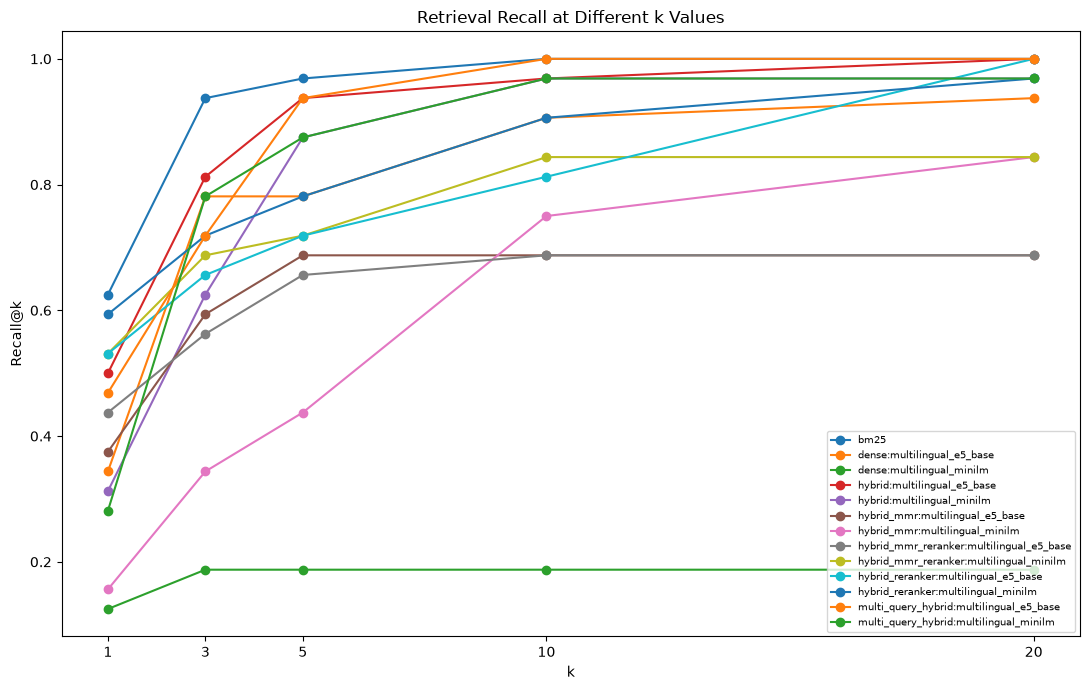

In [44]:
# Recall@k curves for the main benchmark methods.
recall_rows = []
for row in model_comparison_df.itertuples(index=False):
    for k in EVALUATION_K_VALUES:
        column = f"recall@{k}"
        if hasattr(row, column.replace("@", "_")):
            # Named tuples rename invalid column characters.
            value = getattr(row, column.replace("@", "_"))
        else:
            value = model_comparison_df.loc[
                model_comparison_df["benchmark_label"]
                == row.benchmark_label,
                column,
            ].iloc[0]

        recall_rows.append(
            {
                "benchmark_label": row.benchmark_label,
                "k": k,
                "recall": float(value),
            }
        )

recall_plot_df = pd.DataFrame(recall_rows)

plt.figure(figsize=(11, 7))
for label, group in recall_plot_df.groupby(
    "benchmark_label"
):
    group = group.sort_values("k")
    plt.plot(
        group["k"],
        group["recall"],
        marker="o",
        label=label,
    )
plt.title("Retrieval Recall at Different k Values")
plt.xlabel("k")
plt.ylabel("Recall@k")
plt.xticks(EVALUATION_K_VALUES)
plt.legend(fontsize=7, loc="best")
plt.tight_layout()
plt.savefig(
    PATHS["figures"] / "recall_at_k_comparison.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

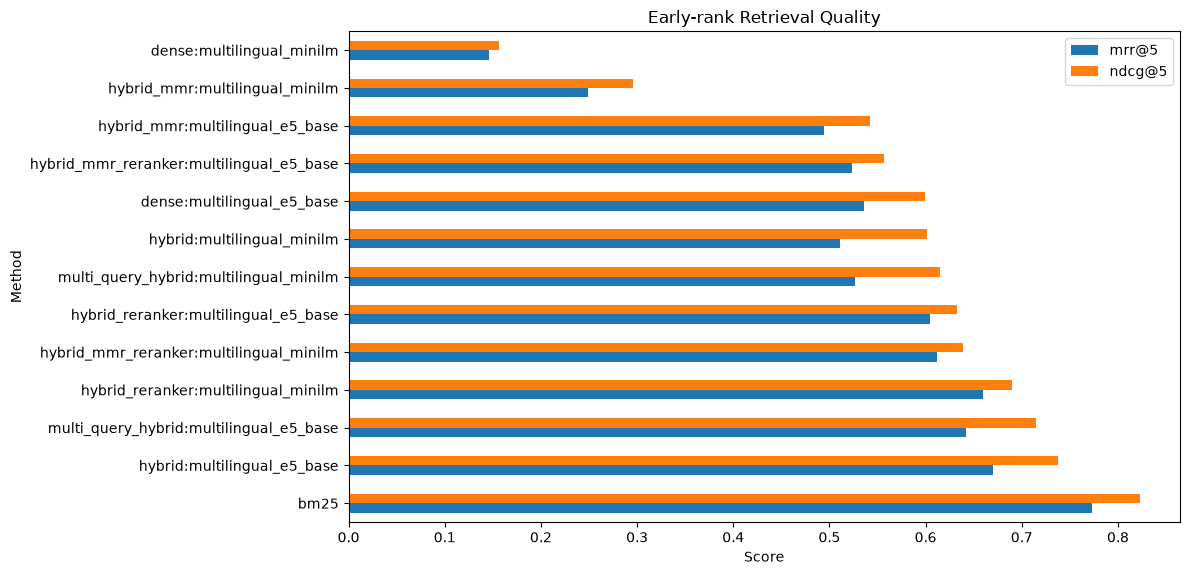

In [45]:
# Early-rank quality comparison.
quality_columns = [
    column
    for column in ["mrr@5", "ndcg@5"]
    if column in model_comparison_df.columns
]

if quality_columns:
    plot_df = model_comparison_df.set_index(
        "benchmark_label"
    )[quality_columns]

    plt.figure(
        figsize=(12, max(5, len(plot_df) * 0.45))
    )
    plot_df.plot(
        kind="barh",
        ax=plt.gca(),
    )
    plt.title("Early-rank Retrieval Quality")
    plt.xlabel("Score")
    plt.ylabel("Method")
    plt.tight_layout()
    plt.savefig(
        PATHS["figures"] / "mrr_ndcg_comparison.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()

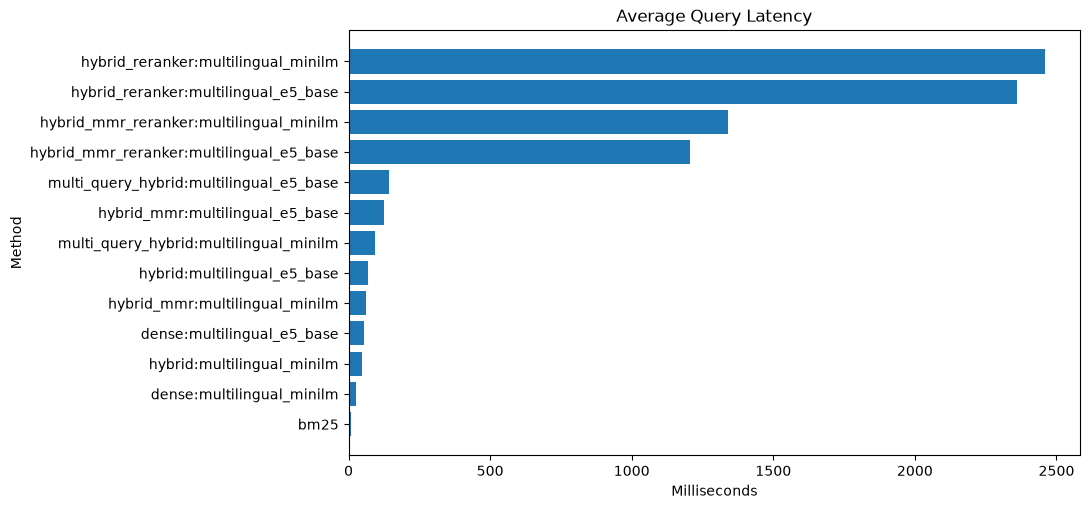

In [46]:
# Average query latency.
latency_plot_df = model_comparison_df.sort_values(
    "latency_ms_mean"
)

plt.figure(
    figsize=(11, max(5, len(latency_plot_df) * 0.4))
)
plt.barh(
    latency_plot_df["benchmark_label"],
    latency_plot_df["latency_ms_mean"],
)
plt.title("Average Query Latency")
plt.xlabel("Milliseconds")
plt.ylabel("Method")
plt.tight_layout()
plt.savefig(
    PATHS["figures"] / "average_query_latency.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

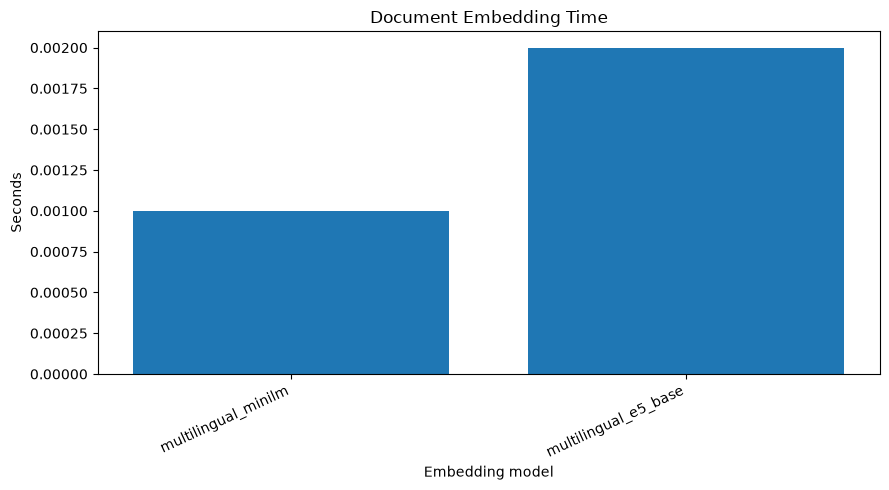

In [47]:
# Embedding generation time.
successful_embeddings_plot_df = embedding_run_df[
    embedding_run_df["status"] == "ready"
].copy()

if not successful_embeddings_plot_df.empty:
    plt.figure(figsize=(9, 5))
    plt.bar(
        successful_embeddings_plot_df["alias"],
        successful_embeddings_plot_df["encode_seconds"],
    )
    plt.title("Document Embedding Time")
    plt.xlabel("Embedding model")
    plt.ylabel("Seconds")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.savefig(
        PATHS["figures"] / "embedding_generation_time.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()

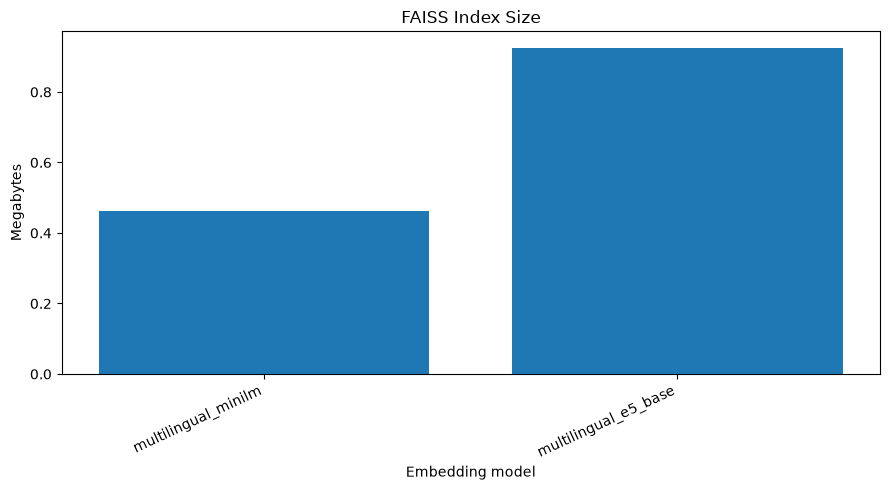

In [48]:
# FAISS index size.
successful_faiss_plot_df = faiss_run_df[
    faiss_run_df["status"] == "ready"
].copy()

if not successful_faiss_plot_df.empty:
    plt.figure(figsize=(9, 5))
    plt.bar(
        successful_faiss_plot_df["alias"],
        successful_faiss_plot_df["index_size_mb"],
    )
    plt.title("FAISS Index Size")
    plt.xlabel("Embedding model")
    plt.ylabel("Megabytes")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.savefig(
        PATHS["figures"] / "faiss_index_size.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()

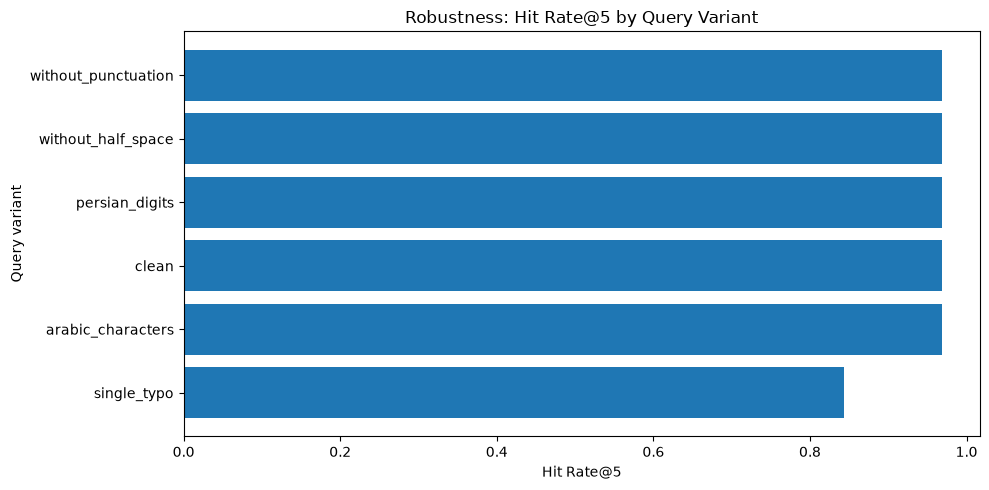

In [49]:
# Robustness comparison.
if not robustness_summary_df.empty:
    plot_df = robustness_summary_df.sort_values(
        "hit_rate_at_5"
    )

    plt.figure(figsize=(10, 5))
    plt.barh(
        plot_df["variant"],
        plot_df["hit_rate_at_5"],
    )
    plt.title("Robustness: Hit Rate@5 by Query Variant")
    plt.xlabel("Hit Rate@5")
    plt.ylabel("Query variant")
    plt.tight_layout()
    plt.savefig(
        PATHS["figures"] / "robustness_hit_rate.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()

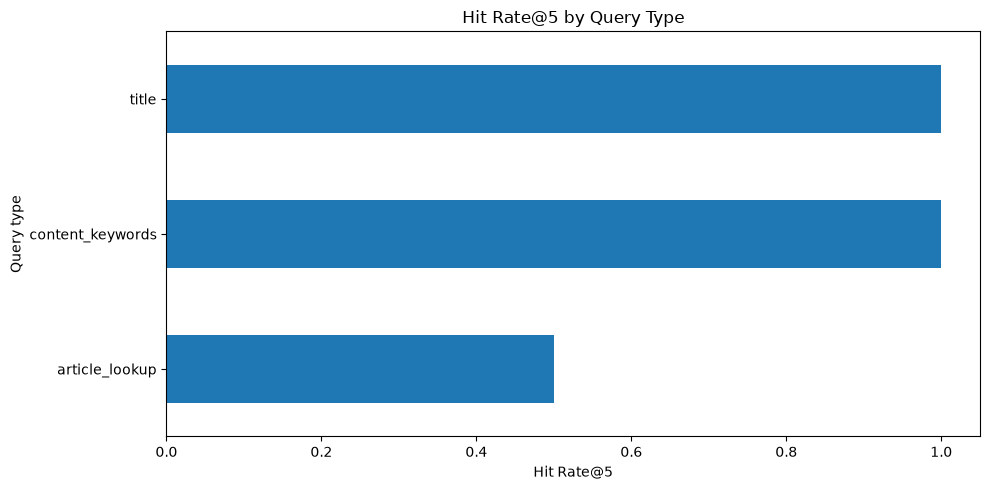

In [50]:
# Performance by query type.
if not performance_by_query_type_df.empty:
    query_type_plot_df = (
        performance_by_query_type_df.groupby("query_type")
        ["hit_rate_at_5"]
        .mean()
        .sort_values()
    )

    plt.figure(figsize=(10, 5))
    query_type_plot_df.plot(kind="barh")
    plt.title("Hit Rate@5 by Query Type")
    plt.xlabel("Hit Rate@5")
    plt.ylabel("Query type")
    plt.tight_layout()
    plt.savefig(
        PATHS["figures"] / "performance_by_query_type.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()

# 27. Select the Best Retriever

The best method is selected from the active benchmark using this priority:

1. nDCG@5
2. MRR@5
3. Recall@5
4. lower mean latency

When a manually reviewed Gold Benchmark is active, the selection is marked
`final_gold`. When the automatically generated Silver Benchmark is active,
the output is marked `provisional_silver` and must not be reported as the
final scientific winner. It can still be used as a development default for
Notebook 03.

In [51]:
selection_columns = [
    column
    for column in [
        "ndcg@5",
        "mrr@5",
        "recall@5",
        "latency_ms_mean",
    ]
    if column in model_comparison_df.columns
]

sort_columns = []
ascending = []

for column in ["ndcg@5", "mrr@5", "recall@5"]:
    if column in model_comparison_df.columns:
        sort_columns.append(column)
        ascending.append(False)

if "latency_ms_mean" in model_comparison_df.columns:
    sort_columns.append("latency_ms_mean")
    ascending.append(True)

selected_models_df = model_comparison_df.sort_values(
    sort_columns,
    ascending=ascending,
).reset_index(drop=True)

BEST_RETRIEVER_ROW = selected_models_df.iloc[0].to_dict()

BENCHMARK_TYPE = str(
    BEST_RETRIEVER_ROW["benchmark_type"]
)
SELECTION_STATUS = (
    "final_gold"
    if BENCHMARK_TYPE == "gold_manual"
    else "provisional_silver"
)

BEST_RETRIEVER_CONFIG = {
    "benchmark_type": BENCHMARK_TYPE,
    "selection_status": SELECTION_STATUS,
    "final_scientific_selection": bool(
        BENCHMARK_TYPE == "gold_manual"
    ),
    "benchmark_label": str(
        BEST_RETRIEVER_ROW["benchmark_label"]
    ),
    "method": str(
        BEST_RETRIEVER_ROW["method"]
    ),
    "dense_alias": (
        str(BEST_RETRIEVER_ROW["dense_alias"])
        if pd.notna(BEST_RETRIEVER_ROW["dense_alias"])
        else DEFAULT_MODEL_ALIAS
    ),
    "embedding_model_name": (
        EMBEDDING_BUNDLES[
            str(BEST_RETRIEVER_ROW["dense_alias"])
        ].model_name
        if pd.notna(
            BEST_RETRIEVER_ROW["dense_alias"]
        )
        and str(BEST_RETRIEVER_ROW["dense_alias"])
        in EMBEDDING_BUNDLES
        else None
    ),
    "reranker_enabled": (
        "reranker"
        in str(BEST_RETRIEVER_ROW["method"])
    ),
    "reranker_model_name": (
        CONFIG["reranker"]["model_name"]
        if "reranker"
        in str(BEST_RETRIEVER_ROW["method"])
        else None
    ),
    "final_k": int(
        CONFIG["retrieval"]["final_k"]
    ),
    "candidate_k": int(
        CONFIG["retrieval"]["candidate_k"]
    ),
    "rrf_k": int(
        CONFIG["retrieval"]["rrf_k"]
    ),
    "bm25_weight": float(
        CONFIG["retrieval"]["bm25_weight"]
    ),
    "dense_weight": float(
        CONFIG["retrieval"]["dense_weight"]
    ),
    "deduplicate": bool(
        CONFIG["retrieval"]["deduplicate"]
    ),
    "use_mmr": bool(
        CONFIG["retrieval"]["use_mmr"]
    ),
    "mmr_lambda": float(
        CONFIG["retrieval"]["mmr_lambda"]
    ),
}

display(
    pd.DataFrame([BEST_RETRIEVER_CONFIG]).T.rename(
        columns={0: "value"}
    )
)

,value
benchmark_type,silver_auto
selection_status,provisional_silver
final_scientific_selection,False
benchmark_label,bm25
method,bm25
dense_alias,multilingual_e5_base
embedding_model_name,None
reranker_enabled,False
reranker_model_name,None
final_k,5


# 28. Export Results and Reproducibility Reports

In [52]:
OUTPUT_PATHS = {
    "benchmark_queries_parquet": (
        PATHS["results"]
        / "benchmark_query_metrics.parquet"
    ),
    "retrieval_results_parquet": (
        PATHS["results"]
        / "retrieval_results.parquet"
    ),
    "model_comparison_csv": (
        PATHS["reports"]
        / "model_comparison.csv"
    ),
    "oracle_filter_comparison_csv": (
        PATHS["reports"]
        / "oracle_filter_comparison.csv"
    ),
    "threshold_calibration_csv": (
        PATHS["reports"]
        / "threshold_calibration.csv"
    ),
    "robustness_results_csv": (
        PATHS["reports"]
        / "robustness_results.csv"
    ),
    "robustness_summary_csv": (
        PATHS["reports"]
        / "robustness_summary.csv"
    ),
    "performance_by_query_type_csv": (
        PATHS["reports"]
        / "performance_by_query_type.csv"
    ),
    "error_analysis_csv": (
        PATHS["reports"]
        / "error_analysis.csv"
    ),
    "best_retriever_yaml": (
        PATHS["reports"]
        / "best_retriever_config.yaml"
    ),
    "metrics_json": (
        PATHS["reports"]
        / "metrics.json"
    ),
    "retrieval_summary_json": (
        PATHS["reports"]
        / "retrieval_summary.json"
    ),
    "execution_report_json": (
        PATHS["reports"]
        / "execution_report.json"
    ),
    "index_manifest_json": (
        PATHS["indexes"]
        / "index_manifest.json"
    ),
}


def json_safe_value(value: Any) -> Any:
    if isinstance(value, dict):
        return {
            str(key): json_safe_value(item)
            for key, item in value.items()
        }
    if isinstance(value, (list, tuple, set)):
        return [
            json_safe_value(item)
            for item in value
        ]
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return (
            None
            if not np.isfinite(value)
            else float(value)
        )
    if isinstance(value, np.bool_):
        return bool(value)
    if isinstance(value, Path):
        return str(value)
    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass
    return value


def dataframe_for_parquet(
    dataframe: pd.DataFrame,
) -> pd.DataFrame:
    output = dataframe.copy()

    for column in output.columns:
        if output[column].map(
            lambda value: isinstance(
                value,
                (list, dict, tuple, set),
            )
        ).any():
            output[column] = output[column].map(
                lambda value: json.dumps(
                    (
                        list(value)
                        if isinstance(
                            value,
                            (tuple, set)
                        )
                        else value
                    ),
                    ensure_ascii=False,
                )
                if isinstance(
                    value,
                    (list, dict, tuple, set),
                )
                else value
            )

    return output


with timed_stage("export_retrieval_results"):
    dataframe_for_parquet(
        benchmark_query_df
    ).to_parquet(
        OUTPUT_PATHS["benchmark_queries_parquet"],
        index=False,
        engine="pyarrow",
    )

    dataframe_for_parquet(
        retrieval_results_df
    ).to_parquet(
        OUTPUT_PATHS["retrieval_results_parquet"],
        index=False,
        engine="pyarrow",
    )

    model_comparison_df.to_csv(
        OUTPUT_PATHS["model_comparison_csv"],
        index=False,
        encoding="utf-8-sig",
    )

    oracle_comparison_df.to_csv(
        OUTPUT_PATHS[
            "oracle_filter_comparison_csv"
        ],
        index=False,
        encoding="utf-8-sig",
    )

    thresholds_df.to_csv(
        OUTPUT_PATHS["threshold_calibration_csv"],
        index=False,
        encoding="utf-8-sig",
    )

    robustness_df.to_csv(
        OUTPUT_PATHS["robustness_results_csv"],
        index=False,
        encoding="utf-8-sig",
    )

    robustness_summary_df.to_csv(
        OUTPUT_PATHS["robustness_summary_csv"],
        index=False,
        encoding="utf-8-sig",
    )

    performance_by_query_type_df.to_csv(
        OUTPUT_PATHS[
            "performance_by_query_type_csv"
        ],
        index=False,
        encoding="utf-8-sig",
    )

    error_analysis_df.to_csv(
        OUTPUT_PATHS["error_analysis_csv"],
        index=False,
        encoding="utf-8-sig",
    )

    OUTPUT_PATHS["best_retriever_yaml"].write_text(
        yaml.safe_dump(
            BEST_RETRIEVER_CONFIG,
            allow_unicode=True,
            sort_keys=False,
        ),
        encoding="utf-8",
    )

INFO | START STAGE: export_retrieval_results
INFO | END STAGE: export_retrieval_results | 0.166 sec


In [53]:
INDEX_MANIFEST = {
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "chunk_count": int(len(chunks_df)),
    "chunk_id_order": chunks_df[
        "chunk_id"
    ].astype(str).tolist(),
    "bm25": {
        "index_path": str(BM25_INDEX_PATH),
        "corpus_path": str(BM25_CORPUS_PATH),
        "config": CONFIG["bm25"],
    },
    "embedding_models": {
        alias: {
            "model_name": bundle.model_name,
            "dimension": bundle.dimension,
            "embedding_path": str(
                bundle.embedding_path
            ),
            "metadata_path": str(
                bundle.metadata_path
            ),
            "faiss_index_path": (
                str(FAISS_BUNDLES[alias].index_path)
                if alias in FAISS_BUNDLES
                else None
            ),
            "chroma_collection": (
                CHROMA_COLLECTIONS[alias].name
                if alias in CHROMA_COLLECTIONS
                else None
            ),
        }
        for alias, bundle in EMBEDDING_BUNDLES.items()
    },
}

OUTPUT_PATHS["index_manifest_json"].write_text(
    json.dumps(
        INDEX_MANIFEST,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

METRICS_EXPORT = {
    "active_benchmark_path": str(
        ACTIVE_BENCHMARK_PATH
    ),
    "benchmark_type": str(
        evaluation_df["benchmark_type"].iloc[0]
    ),
    "query_count": int(len(evaluation_df)),
    "k_values": EVALUATION_K_VALUES,
    "model_comparison": model_comparison_df.replace(
        {np.nan: None}
    ).to_dict(orient="records"),
    "oracle_filter_comparison": (
        oracle_comparison_df.replace(
            {np.nan: None}
        ).to_dict(orient="records")
    ),
    "threshold_calibration": thresholds_df.replace(
        {np.nan: None}
    ).to_dict(orient="records"),
    "robustness_summary": robustness_summary_df.replace(
        {np.nan: None}
    ).to_dict(orient="records"),
    "performance_by_query_type": (
        performance_by_query_type_df.replace(
            {np.nan: None}
        ).to_dict(orient="records")
    ),
    "best_retriever": BEST_RETRIEVER_CONFIG,
}

OUTPUT_PATHS["metrics_json"].write_text(
    json.dumps(
        json_safe_value(METRICS_EXPORT),
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

25692

In [54]:
TOTAL_RUNTIME_SECONDS = round(
    time.perf_counter() - PIPELINE_STARTED_AT,
    3,
)

RETRIEVAL_SUMMARY = {
    "run_id": RUN_ID,
    "status": (
        "completed_with_errors"
        if PIPELINE_ERRORS
        else "completed_with_warnings"
        if PIPELINE_WARNINGS
        else "completed"
    ),
    "benchmark_type": str(
        evaluation_df["benchmark_type"].iloc[0]
    ),
    "benchmark_queries": int(
        len(evaluation_df)
    ),
    "chunks_indexed": int(
        len(chunks_df)
    ),
    "documents_indexed": int(
        chunks_df["document_id"].nunique()
    ),
    "embedding_models_ready": sorted(
        EMBEDDING_BUNDLES.keys()
    ),
    "faiss_indexes_ready": sorted(
        FAISS_BUNDLES.keys()
    ),
    "chroma_collections_ready": sorted(
        CHROMA_COLLECTIONS.keys()
    ),
    "reranker_status": RERANKER_INFO["status"],
    "best_retriever": BEST_RETRIEVER_CONFIG,
    "failed_answerable_queries_at_5": int(
        len(error_analysis_df)
    ),
    "errors_count": len(PIPELINE_ERRORS),
    "warnings_count": len(PIPELINE_WARNINGS),
    "total_runtime_seconds": TOTAL_RUNTIME_SECONDS,
    "notebook03_input": {
        "chunks": str(PATHS["chunks"]),
        "index_manifest": str(
            OUTPUT_PATHS["index_manifest_json"]
        ),
        "best_retriever_config": str(
            OUTPUT_PATHS["best_retriever_yaml"]
        ),
    },
}

EXECUTION_REPORT = {
    **ENVIRONMENT_INFO,
    "run_finished_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "total_runtime_seconds": TOTAL_RUNTIME_SECONDS,
    "stage_timings_seconds": STAGE_TIMINGS,
    "config": CONFIG,
    "input_validation": INPUT_VALIDATION,
    "active_benchmark_path": str(
        ACTIVE_BENCHMARK_PATH
    ),
    "embedding_runs": EMBEDDING_RUN_ROWS,
    "faiss_runs": FAISS_RUN_ROWS,
    "chroma_runs": CHROMA_RUN_ROWS,
    "reranker": RERANKER_INFO,
    "best_retriever": BEST_RETRIEVER_CONFIG,
    "output_paths": {
        key: str(path)
        for key, path in OUTPUT_PATHS.items()
    },
    "log_path": str(LOG_PATH),
    "errors": PIPELINE_ERRORS,
    "warnings": PIPELINE_WARNINGS,
}

OUTPUT_PATHS["retrieval_summary_json"].write_text(
    json.dumps(
        json_safe_value(RETRIEVAL_SUMMARY),
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

OUTPUT_PATHS["execution_report_json"].write_text(
    json.dumps(
        json_safe_value(EXECUTION_REPORT),
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

display(
    pd.DataFrame([RETRIEVAL_SUMMARY]).T.rename(
        columns={0: "value"}
    )
)

,value
run_id,20260715_015615
status,completed
benchmark_type,silver_auto
benchmark_queries,37
chunks_indexed,316
documents_indexed,15
embedding_models_ready,"[multilingual_e5_base, multilingual_minilm]"
faiss_indexes_ready,"[multilingual_e5_base, multilingual_minilm]"
chroma_collections_ready,"[multilingual_e5_base, multilingual_minilm]"
reranker_status,ready


# 29. Final Integrity Check

The notebook verifies:

- all required reports exist
- every embedding matrix matches the chunk count
- every FAISS index contains all chunks
- all retrieved chunk IDs exist
- the selected retriever references a successful model
- exported Parquet files can be loaded

In [55]:
REQUIRED_OUTPUT_KEYS = [
    "benchmark_queries_parquet",
    "retrieval_results_parquet",
    "model_comparison_csv",
    "threshold_calibration_csv",
    "best_retriever_yaml",
    "metrics_json",
    "retrieval_summary_json",
    "execution_report_json",
    "index_manifest_json",
]

missing_outputs = [
    key
    for key in REQUIRED_OUTPUT_KEYS
    if not OUTPUT_PATHS[key].exists()
]

if missing_outputs:
    raise AssertionError(
        f"Required retrieval outputs are missing: {missing_outputs}"
    )

for alias, bundle in EMBEDDING_BUNDLES.items():
    assert bundle.embeddings.shape[0] == len(chunks_df)
    assert np.isfinite(bundle.embeddings).all()

for alias, bundle in FAISS_BUNDLES.items():
    assert int(bundle.index.ntotal) == len(chunks_df)

known_chunk_ids = set(
    chunks_df["chunk_id"].astype(str)
)
retrieved_chunk_ids = set(
    retrieval_results_df["chunk_id"].astype(str)
)

unknown_retrieved_ids = (
    retrieved_chunk_ids - known_chunk_ids
)
assert not unknown_retrieved_ids, (
    f"Unknown retrieved chunk IDs: "
    f"{sorted(unknown_retrieved_ids)[:10]}"
)

reloaded_query_metrics = pd.read_parquet(
    OUTPUT_PATHS["benchmark_queries_parquet"],
    engine="pyarrow",
)
reloaded_retrieval_results = pd.read_parquet(
    OUTPUT_PATHS["retrieval_results_parquet"],
    engine="pyarrow",
)

assert len(reloaded_query_metrics) == len(
    benchmark_query_df
)
assert len(reloaded_retrieval_results) == len(
    retrieval_results_df
)


bounded_metric_columns = [
    column
    for column in benchmark_query_df.columns
    if re.match(
        r"^(hit_rate|precision|recall|mrr|ndcg|map)@\\d+$",
        column,
    )
]

for column in bounded_metric_columns:
    values = benchmark_query_df[column].dropna().astype(float)
    assert values.between(
        0.0,
        1.0,
        inclusive="both",
    ).all(), (
        f"Metric {column} contains values outside [0, 1]. "
        f"Range: {values.min()} to {values.max()}"
    )

selected_dense_alias = BEST_RETRIEVER_CONFIG[
    "dense_alias"
]
if BEST_RETRIEVER_CONFIG["method"] != "bm25":
    assert selected_dense_alias in EMBEDDING_BUNDLES

print("✅ Retrieval pipeline outputs passed the integrity check.")
print()
for name, path in OUTPUT_PATHS.items():
    marker = "✅" if path.exists() else "❌"
    size_mb = (
        round(
            path.stat().st_size / (1024 ** 2),
            4,
        )
        if path.exists()
        else None
    )
    print(f"{marker} {name}: {path} | {size_mb} MB")

✅ Retrieval pipeline outputs passed the integrity check.

✅ benchmark_queries_parquet: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\retrieval\results\benchmark_query_metrics.parquet | 0.0379 MB
✅ retrieval_results_parquet: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\retrieval\results\retrieval_results.parquet | 0.478 MB
✅ model_comparison_csv: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\retrieval\reports\model_comparison.csv | 0.0062 MB
✅ oracle_filter_comparison_csv: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\retrieval\reports\oracle_filter_comparison.csv | 0.0012 MB
✅ threshold_calibration_csv: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\retrieval\reports\threshold_calibration.csv | 0.0017 MB
✅ robustness_results_csv: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\retrieval\reports\robustness_results.csv | 0.0377 MB
✅ robustness_summary_csv: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\retrieval\reports\robustness_summary.csv | 0.0004 MB
✅ performance_b

In [56]:
print("=" * 76)
print("UNIVERSITY RAG — RETRIEVAL PIPELINE COMPLETED")
print("=" * 76)
print(f"Chunks indexed          : {RETRIEVAL_SUMMARY['chunks_indexed']}")
print(f"Documents indexed       : {RETRIEVAL_SUMMARY['documents_indexed']}")
print(f"Benchmark queries       : {RETRIEVAL_SUMMARY['benchmark_queries']}")
print(f"Benchmark type          : {RETRIEVAL_SUMMARY['benchmark_type']}")
print(
    "Embedding models ready : "
    f"{', '.join(RETRIEVAL_SUMMARY['embedding_models_ready'])}"
)
print(
    "FAISS indexes ready     : "
    f"{', '.join(RETRIEVAL_SUMMARY['faiss_indexes_ready'])}"
)
print(f"Reranker status         : {RETRIEVAL_SUMMARY['reranker_status']}")
print(
    "Best retriever          : "
    f"{BEST_RETRIEVER_CONFIG['benchmark_label']}"
)
print(
    "Failed positive queries : "
    f"{RETRIEVAL_SUMMARY['failed_answerable_queries_at_5']}"
)
print(f"Errors                   : {RETRIEVAL_SUMMARY['errors_count']}")
print(f"Warnings                 : {RETRIEVAL_SUMMARY['warnings_count']}")
print(f"Runtime (seconds)        : {RETRIEVAL_SUMMARY['total_runtime_seconds']}")
print(
    "Notebook 03 config      : "
    f"{OUTPUT_PATHS['best_retriever_yaml']}"
)
print("=" * 76)

UNIVERSITY RAG — RETRIEVAL PIPELINE COMPLETED
Chunks indexed          : 316
Documents indexed       : 15
Benchmark queries       : 37
Benchmark type          : silver_auto
Embedding models ready : multilingual_e5_base, multilingual_minilm
FAISS indexes ready     : multilingual_e5_base, multilingual_minilm
Reranker status         : ready
Best retriever          : bm25
Failed positive queries : 1
Errors                   : 0
Warnings                 : 0
Runtime (seconds)        : 342.805
Notebook 03 config      : D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\retrieval\reports\best_retriever_config.yaml


# References and Method Notes

The notebook design follows standard information retrieval practice:

- BM25 as a lexical baseline
- multilingual sentence embeddings for dense retrieval
- normalized vectors with exact FAISS inner-product search
- Reciprocal Rank Fusion for sparse–dense combination
- cross-encoder reranking for early-rank precision
- MMR for result diversity
- separate retriever evaluation before answer generation

Model-specific query and passage prefixes are configured in `retrieval_config.yaml`. For example, multilingual E5 uses `query:` and `passage:` prefixes.